# Responsiveness schema — a guided tour on 10 random recordings

This notebook shows what every table of the responsiveness schema contains and how to use it, on the pilot
schema **`tobiasr_responsiveness_v7`**: 10 recordings drawn at random (seed 20261116) from 9 animals of the drift
cohort — 4 moving-grating, 4 natural-image and 2 checkerboard receptive-field recordings — each on three trace types
(dF/F0, CASCADE 25 ms, OASIS). Everything is read-only.

### How to read every figure

| mark | meaning |
|---|---|
| **yellow band** | the stimulus **on screen**. From the photodiode (LED) where the rig has one (animals from Nov 2025), otherwise DataJoint time + the display latency |
| **black tick / dotted line** | the **DataJoint onset**: `event.Event.event_start_time`, the DAQ edge of Bonsai's stimulus plateau |
| **red tick / dashed line** | the **LED onset**: the photodiode's bright→dark flip of the screen-corner square (`ScreenTiming.Onset.diode_on`) |
| **blue bar** | the **baseline window** a read-out used |
| **red bar** | the **response window** a read-out used |

Window bars are drawn from the edges `Readout` stored when it computed (`resp_start_s`, `resp_stop_s`,
`base_start_s`, `base_stop_s`, relative to the DataJoint onset), never recomputed for the plot. Time axes of PSTHs are
**time from the DataJoint onset**.

### The schema

```
UNIVERSAL, event-independent
  scan.Scan ─► ScanQuality             detector gain / offset from the raw TIFF (per scan, curation-independent)
  imaging.Fluorescence ─► Quality(.Cell)        neuropil sweep; per cell kurtosis, r(F, Fneu), photons/s
                     └─► TraceQuality(.Cell)   per trace type (TraceSource): SNR, CASCADE noise, event rate, max
PARADIGM (trial schema)
  trial.TrialEvent ─► EventSet(.Onset) ◄─ EventSelector       onsets + condition labels; random-onset controls
                      └─► ScreenTiming(.Onset)                 photodiode (LED) onsets, per-recording latency
UNIVERSAL, event-dependent (curation x trace type x event set x own parameter set)
  ReadoutParamSet ─► Readout(.Cell, .Condition)   explicit baseline / response windows, measure, test; trial_resp
  ZetaParamSet    ─► Zeta(.Cell, .Condition)      time-series ZETA (copied across curations for identical traces)
STIMULUS-SPECIFIC
  TuningParamSet  ─► DirectionTuning(.Cell)       Mazurek, Kager & Van Hooser 2014 measures, angle convention
DECISIONS
  CellRule ─► cells(rule)                         named thresholds, applied by query
```

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import datajoint as dj

_conf = os.path.expanduser("~/adamacs_ingest/dj_local_conf.json")      # lab config (host, user); not part of this notebook
if os.path.exists(_conf): dj.config.load(_conf)
dj.config["database.use_tls"] = False
dj.config["display.limit"] = 8
dj.conn().query("SET SESSION transaction_read_only = 1")             # read-only, enforced by the server
assert dj.conn().query("SELECT @@transaction_read_only").fetchone()[0] == 1
for p in (os.path.expanduser("~/resp_pilot/adamacs_ingest"), os.path.expanduser("~/adamacs_ingest")):   # first checkout with v7 helpers
    if os.path.exists(os.path.join(p, "adamacs", "responsiveness", "photodiode.py")):
        sys.path[:] = [p] + [q for q in sys.path if q not in (p, "", os.getcwd())]; break
from adamacs.responsiveness import photodiode as PD                  # pure helpers, no schema activation

vm = lambda n: dj.create_virtual_module(n, n, create_schema=False, create_tables=False)
r, imaging, event, trial, session = (vm("tobiasr_responsiveness_v7"), vm("roselab_imaging"), vm("roselab_event"),
                                     vm("roselab_trial"), vm("roselab_session"))

mpl.rcParams.update({"figure.dpi": 105, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False, "font.family": "DejaVu Sans"})
COL = {"dff0_r2": "#2b2d42", "cascade25": "#e76f51", "oasis": "#2a9d8f", "stim": "#ffd166", "resp": "#e63946",
       "base": "#457b9d", "dj": "#111111", "led": "#d62828", "null": "#adb5bd", "accent": "#7b2cbf"}
LBL = {"dff0_r2": "dF/F0 (recipe 2)", "cascade25": "CASCADE 25 ms", "oasis": "OASIS (suite2p)"}
LEGEND = [Patch(color=COL["stim"], alpha=.5, label="stimulus on screen"), Line2D([], [], color=COL["dj"], ls=":", label="DataJoint onset"),
          Line2D([], [], color=COL["led"], ls="--", label="LED (photodiode) onset"),
          Patch(color=COL["base"], label="baseline window"), Patch(color=COL["resp"], label="response window"),
          Patch(color="#9aa0a6", alpha=.35, label="other stimulus, not in the event set")]

In [2]:
# ---- recordings in the pilot -------------------------------------------------------------------------------------
MAIN = {"gratings": "gratings", "nat_images_repeated": "images", "rf_checkerboard": "rf"}
# standard window per paradigm = Leon's export windows (v1-drift-audit): gratings read-out 2, images read-out 3;
# the checkerboard has no export window: read-out 1 (stimulus mean minus the 0.5 s before onset)
# STANDARD windows per paradigm and trace (ReadoutParamSet):
#   gratings, every trace: 16  stimulus on screen [on, off), raw trial values; tested vs frames [on - 60, on - 10) (after OFF decay, before CASCADE leak)
#   images, OASIS / dF/F0:  3  Leon's export window, frames [on + 3, on + 3 + n), raw
#   images, CASCADE:       11  v1-drift-audit consensus window (leave-one-animal-out), frames [on - 1, on + 15), raw
#   checkerboard:           1  stimulus mean minus the 0.5 s before onset (no export window)
def std(selector, source):
    sel = selector.replace("_random", "")
    if sel == "nat_images_repeated": return 11 if source == "cascade25" else 3
    return {"gratings": 16, "rf_checkerboard": 1}[sel]
TUNE = {"readout_idx": 16, "tuning_idx": 1, "trace_source": "cascade25"}   # standard window, Mazurek indices on rectified means
AUDIT_TUNE = {"readout_idx": 2, "tuning_idx": 2, "trace_source": "oasis"}  # audit g1: OASIS, Leon's export window, unrectified
rows = []
for t in (r.ResponseTask & [{"event_selector": s} for s in MAIN]).fetch(as_dict=True):
    rows.append(dict(scan_id=t["scan_id"], session_id=t["session_id"], paramset_idx=t["paramset_idx"], curation_id=t["curation_id"],
                     selector=t["event_selector"], paradigm=MAIN[t["event_selector"]]))
REC = pd.DataFrame(rows).drop_duplicates("scan_id")
REC = REC.merge(pd.DataFrame((session.Session & REC[["session_id"]].to_dict("records")).fetch("session_id", "subject", "session_datetime", as_dict=True)), on="session_id")
st = pd.DataFrame((r.ScreenTiming & REC[["scan_id"]].to_dict("records")).fetch(as_dict=True))
REC = REC.merge(st[["scan_id", "event_selector", "has_diode", "latency_s", "latency_iqr_s", "n_detected"]], left_on=["scan_id", "selector"],
                right_on=["scan_id", "event_selector"], how="left").drop(columns="event_selector")
REC = REC.sort_values(["paradigm", "session_datetime"]).reset_index(drop=True)
REC["date"] = REC.session_datetime.astype(str).str[:10]
def key(row): return {k: row[k] for k in ("session_id", "scan_id", "paramset_idx", "curation_id")}
REC[["paradigm", "subject", "date", "scan_id", "curation_id", "has_diode", "latency_s", "latency_iqr_s", "n_detected"]]

,paradigm,subject,date,scan_id,curation_id,has_diode,latency_s,latency_iqr_s,n_detected
0,gratings,ROS-1841,2024-07-01,scan9FOW97IH,2,0,NaN,NaN,0
1,gratings,ROS-2083,2025-05-19,scan9FU80KDL,1,0,NaN,NaN,0
2,gratings,ROS-2147,2025-08-29,scan9FVWM3U6,1,0,NaN,NaN,0
3,gratings,ROS-2328,2026-08-09,scan9G1LZPV1,1,1,0.082750,0.047050,180
4,images,ROS-2077,2025-04-28,scan9FTVHVAJ,1,0,NaN,NaN,0
5,images,ROS-2209,2025-12-06,scan9FXJKSDL,2,1,0.085525,0.015863,1000
6,images,ROS-2328,2026-08-11,scan9G1N8H67,3,1,0.098700,0.070775,455
7,images,ROS-2359,2026-10-11,scan9G2NNB6X,2,1,0.118000,0.045075,1000
8,rf,ROS-2209,2025-11-24,scan9FXCKHW1,2,1,0.087050,0.019400,390
9,rf,ROS-2210,2025-11-29,scan9FXFFH88,3,1,0.101075,0.013225,700


In [3]:
# ---- helpers ------------------------------------------------------------------------------------------------------
def frame_times(k):
    return (event.Event & {"session_id": k["session_id"], "scan_id": k["scan_id"]} & 'event_type LIKE "%%2p_frames%%"').fetch(
        "event_start_time", order_by="event_start_time").astype(float)

def trace(k, mask, source):
    src = (r.TraceSource & {"trace_source": source}).fetch1()
    kk = {**{a: k[a] for a in ("session_id", "scan_id", "paramset_idx", "curation_id")}, "mask": int(mask), "fluo_channel": 0}
    if src["extraction_method"]:
        return np.asarray((imaging.Activity.Trace & kk & {"extraction_method": src["extraction_method"]}).fetch1("activity_trace"), float)
    return np.asarray((imaging.Dff0.Trace & kk & {"dff_paramset_idx": src["dff_paramset_idx"]}).fetch1("dff"), float)

def timing(k, selector):
    # DataJoint and LED times of every onset of an event set (LED NaN where no diode); latency used for screen time
    q = r.EventSet.Onset * event.Event.proj("event_end_time") & {"scan_id": k["scan_id"], "event_selector": selector}
    t0, t1, sh, cond = q.fetch("event_start_time", "event_end_time", "shift_s", "condition", order_by="onset_idx")
    t0 = t0.astype(float) + sh.astype(float); t1 = t1.astype(float) + sh.astype(float)
    led_on = np.full(t0.size, np.nan); led_off = np.full(t0.size, np.nan)
    s = (r.ScreenTiming & {"scan_id": k["scan_id"], "event_selector": selector}).fetch(as_dict=True)
    diode = bool(s and s[0]["has_diode"] and s[0]["latency_s"] is not None)
    if diode:
        on, off = (r.ScreenTiming.Onset * r.EventSet.Onset & {"scan_id": k["scan_id"], "event_selector": selector}).fetch(
            "diode_on", "diode_off", order_by="onset_idx")
        led_on = np.array([np.nan if v is None else float(v) for v in on]); led_off = np.array([np.nan if v is None else float(v) for v in off])
        lat = float(s[0]["latency_s"])
    else:
        lat = float((r.EventSelector & {"event_selector": selector}).fetch1()["display_latency_s"])
    screen_on = np.where(np.isfinite(led_on), led_on, t0 + lat); screen_off = screen_on + (t1 - t0)                   # duration from the event; diode offsets are unreliable for small patches
    return dict(t0=t0, t1=t1, cond=np.asarray(cond).astype(str), led_on=led_on, led_off=led_off, lat=lat,
                screen_on=screen_on, screen_off=screen_off, has_diode=diode)

def peri(x, ft, t0, pre=1.0, post=4.0, dt=1/30):
    n = min(len(x), len(ft)); x, ft = x[:n], ft[:n]
    grid = np.arange(-pre, post, dt)
    return grid, np.vstack([np.interp(t + grid, ft, x, left=np.nan, right=np.nan) for t in t0])

def psth(ax, grid, M, color, label=None, scale=False):
    m, s = np.nanmean(M, 0), np.nanstd(M, 0) / np.sqrt(np.sum(np.isfinite(M), 0))
    if scale:
        f = np.nanmax(np.abs(m)) or 1; m, s = m / f, s / f
    ax.fill_between(grid, m - s, m + s, color=color, alpha=0.25, lw=0); ax.plot(grid, m, color=color, lw=1.5, label=label)

def mark_psth(ax, tm, readout=None, cascade=None):
    # stimulus on screen (median), DataJoint onset, LED onset, and the stored windows of one Readout row
    dur = np.nanmedian(tm["t1"] - tm["t0"]); s0 = np.nanmedian(tm["screen_on"] - tm["t0"])
    ax.axvspan(s0, s0 + dur, color=COL["stim"], alpha=.35, lw=0)
    ax.axvline(0, color=COL["dj"], ls=":", lw=1)
    if tm["has_diode"]: ax.axvline(np.nanmedian(tm["led_on"] - tm["t0"]), color=COL["led"], ls="--", lw=1)
    if readout is not None:
        ax.axvspan(readout["resp_start_s"], readout["resp_stop_s"], ymin=0, ymax=.06, color=COL["resp"], lw=0)
        if readout["base_stop_s"] is not None:
            ax.axvspan(readout["base_start_s"], readout["base_stop_s"], ymin=0, ymax=.06, color=COL["base"], lw=0)
    if cascade is not None:            # CASCADE's own standard window where it differs (images: read-out 11)
        ax.axvspan(cascade["resp_start_s"], cascade["resp_stop_s"], ymin=.07, ymax=.11, color=COL["cascade25"], lw=0)

def other_events(k, selector, tm, win):
    # presentations of the same stimulus family that are NOT in the event set (e.g. the single natural images between repeats)
    like = (r.EventSelector & {"event_selector": selector}).fetch1("event_type_like").replace("%", "%%")
    s_, e_ = (event.Event & {"session_id": k["session_id"], "scan_id": k["scan_id"]} & f'event_type LIKE "{like}"'
              & f"event_start_time > {win[0] - 2}" & f"event_start_time < {win[1]}").fetch("event_start_time", "event_end_time")
    s_, e_ = s_.astype(float), e_.astype(float)
    keep = np.array([np.min(np.abs(tm["t0"] - x)) > 1e-3 for x in s_], bool) if s_.size else np.zeros(0, bool)
    return s_[keep] + tm["lat"], e_[keep] + tm["lat"]

def mark_timeline(ax, tm, win, labels=None, others=None):
    if others is not None:
        for a_, b_ in zip(*others): ax.axvspan(a_, b_, color="#9aa0a6", alpha=.3, lw=0)
    for i in np.flatnonzero((tm["t0"] > win[0]) & (tm["t0"] < win[1])):
        ax.axvspan(tm["screen_on"][i], tm["screen_off"][i], color=COL["stim"], alpha=.35, lw=0)
        ax.axvline(tm["t0"][i], ymin=.92, ymax=1, color=COL["dj"], lw=1.4)
        if np.isfinite(tm["led_on"][i]): ax.axvline(tm["led_on"][i], ymin=.84, ymax=.92, color=COL["led"], lw=1.4)
        if labels is not None: ax.text(tm["screen_on"][i], .78, labels[i], transform=ax.get_xaxis_transform(), fontsize=6, color="#7a5c00")

def readout_row(k, selector, src, idx):
    q = r.Readout & k & {"event_selector": selector, "trace_source": src, "readout_idx": idx}
    return q.fetch1() if q else None

def soma(k):
    return set((imaging.MaskClassification.MaskType & k & 'mask_type="soma"').fetch("mask").tolist())

## 1. One trial, every mark explained

A single presentation of a recording with a photodiode (a grating recording if one has a diode, else an image
recording). The bars are the paradigm's **standard window**, stored by `Readout`:

| paradigm | trace | read-out | response | baseline |
|---|---|---|---|---|
| gratings | all | 16 | stimulus on screen, frames [on, off), raw per-trial value | frames [on − 60, on − 10) (−2.0 to −0.33 s), used by the test |
| images | OASIS, dF/F0 | 3 | Leon's export window, frames [on + 3, on + 3 + n), n = off − on + 2 of trial 1 | none (raw) |
| images | CASCADE | 11 | audit consensus window (leave-one-animal-out), frames [on − 1, on + 15) | none (raw) |
| checkerboard | all | 1 | [onset, offset) | [onset − 0.5 s, onset) |

The grating baseline starts after the previous grating's OFF response has decayed (−2.0 s) and ends 10 frames before
the on-screen onset, before CASCADE's non-causal 25 ms kernel starts to rise (section 11); the CASCADE image window
starts 1 frame early for the same reason. Images have no baseline: the grey gap
still holds the previous image's response (audit) — image responsiveness is ZETA, reliability the oracle.

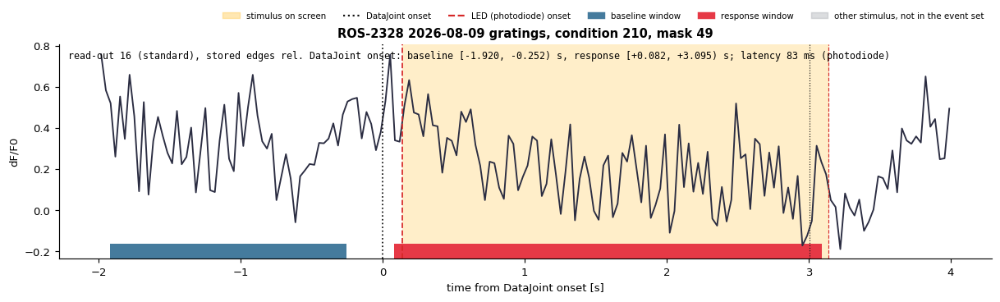

In [4]:
cand = REC[REC.has_diode == True]
row = (cand[cand.paradigm == "gratings"].iloc[0] if (cand.paradigm == "gratings").any() else cand.iloc[0]) if len(cand) else REC.iloc[0]
k = key(row); tm = timing(k, row.selector); ft = frame_times(k)
z = (r.Zeta.Cell & k & {"event_selector": row.selector, "trace_source": "oasis", "zeta_idx": 1}).proj("zeta_p").fetch(format="frame").reset_index()
m = int(z.sort_values("zeta_p").iloc[0]["mask"]); x = trace(k, m, "dff0_r2"); RIDX = std(row.selector, "dff0_r2"); ro8 = readout_row(k, row.selector, "dff0_r2", RIDX)
i = int(np.argmin(np.abs(tm["t0"] - np.median(tm["t0"])))); t = tm["t0"][i]
fig, ax = plt.subplots(figsize=(12, 3.6))
n = min(len(ft), len(x)); sel = (ft[:n] > t - 2) & (ft[:n] < t + 4)
ax.plot(ft[:n][sel] - t, x[:n][sel], color=COL["dff0_r2"], lw=1.3)
ax.axvspan(tm["screen_on"][i] - t, tm["screen_off"][i] - t, color=COL["stim"], alpha=.35, lw=0)
ax.axvline(0, color=COL["dj"], ls=":", lw=1.2); ax.axvline(tm["t1"][i] - t, color=COL["dj"], ls=":", lw=.8)
if np.isfinite(tm["led_on"][i]):
    ax.axvline(tm["led_on"][i] - t, color=COL["led"], ls="--", lw=1.2); ax.axvline(tm["led_off"][i] - t, color=COL["led"], ls="--", lw=.8)
if ro8:
    ax.axvspan(ro8["resp_start_s"], ro8["resp_stop_s"], ymin=0, ymax=.07, color=COL["resp"], lw=0)
    if ro8["base_stop_s"] is not None: ax.axvspan(ro8["base_start_s"], ro8["base_stop_s"], ymin=0, ymax=.07, color=COL["base"], lw=0)
    bt = f"[{ro8['base_start_s']:+.3f}, {ro8['base_stop_s']:+.3f}) s" if ro8["base_stop_s"] is not None else "none"
    ax.text(.01, .97, f"read-out {RIDX} (standard), stored edges rel. DataJoint onset: baseline {bt}, "
            f"response [{ro8['resp_start_s']:+.3f}, {ro8['resp_stop_s']:+.3f}) s; latency {ro8['latency_s']*1e3:.0f} ms ({ro8['latency_source']})",
            transform=ax.transAxes, va="top", fontsize=8, family="monospace")
ax.set(xlabel="time from DataJoint onset [s]", ylabel="dF/F0", title=f"{row.subject} {row.date} {row.paradigm}, condition {tm['cond'][i]}, mask {m}")
ax.legend(handles=LEGEND, fontsize=7, ncol=6, loc="lower right", bbox_to_anchor=(1, 1.08)); plt.tight_layout()

## 2. Timing: DataJoint onsets, LED onsets and the display latency

DataJoint onsets are DAQ edges of Bonsai's stimulus plateau; the 2P frame times are the DAQ frame clock (both checked
against the Bonsai logs by the v1-drift-audit). The image reaches the screen later. Where the rig has a photodiode,
`ScreenTiming` measures it per presentation (audit algorithm: first bright→dark flip of the corner square within
[−150, +400] ms; ±8 ms resolution). Left: the raw diode around four onsets. Middle: per-presentation latency for
every diode recording of the pilot. Right: population response (z, soma, CASCADE) against the DataJoint onset.

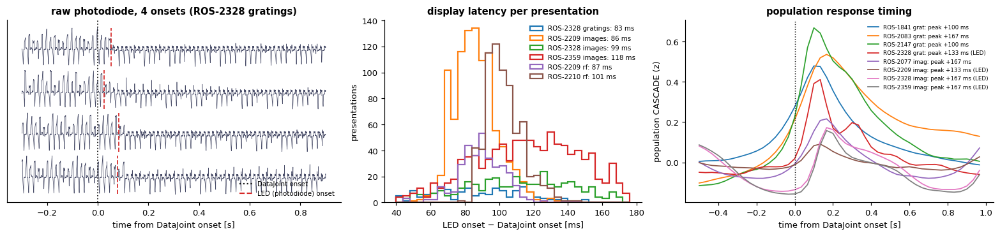

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6), gridspec_kw={"width_ratios": [1.3, 1, 1.2]})
dio = REC[REC.has_diode == True]
if len(dio):
    row = dio.iloc[0]; k = key(row); tm = timing(k, row.selector)
    path = (event.BehaviorRecording.File & {"scan_id": row.scan_id}).fetch("filepath")[0]
    tr_, sr, _ = PD.read_photodiode(path)
    for j, i in enumerate(range(10, 14)):
        t = tm["t0"][i]; a, b = int((t - .3) * sr), int((t + .9) * sr)
        seg = tr_[a:b]; ax[0].plot(np.arange(a, b) / sr - t, (seg - seg.min()) / (np.ptp(seg) or 1) - j * 1.1, color="#4a4e69", lw=.5)
        ax[0].plot([tm["led_on"][i] - t] * 2, [-j * 1.1, -j * 1.1 + 1], color=COL["led"], ls="--", lw=1.2)
    ax[0].axvline(0, color=COL["dj"], ls=":", lw=1.2)
    ax[0].legend(handles=LEGEND[1:3], fontsize=7, loc="lower right")
    ax[0].set(xlabel="time from DataJoint onset [s]", yticks=[], title=f"raw photodiode, 4 onsets ({row.subject} {row.paradigm})")
    for _, rw in dio.iterrows():
        tmx = timing(key(rw), rw.selector); lat = (tmx["led_on"] - tmx["t0"]) * 1e3
        ax[1].hist(lat[np.isfinite(lat)], bins=np.arange(40, 180, 4), histtype="step", lw=1.5, label=f"{rw.subject} {rw.paradigm}: {np.nanmedian(lat):.0f} ms")
    ax[1].set(xlabel="LED onset − DataJoint onset [ms]", ylabel="presentations", title="display latency per presentation"); ax[1].legend(fontsize=7)
else:
    ax[0].text(.5, .5, "no diode recording in the pilot", ha="center"); ax[1].axis("off")
for _, rw in REC[REC.paradigm != "rf"].iterrows():
    k = key(rw); tm = timing(k, rw.selector); ft = frame_times(k); Ms = []
    for m in sorted(soma(k))[:150]:
        x = trace(k, m, "cascade25"); x = (x - np.nanmean(x)) / (np.nanstd(x) + 1e-9); g, M = peri(x, ft, tm["t0"], .5, 1.0); Ms.append(np.nanmean(M, 0))
    mu = np.nanmean(Ms, 0); ax[2].plot(g, mu, lw=1.2, label=f"{rw.subject} {rw.paradigm[:4]}: peak {g[np.argmax(mu)]*1e3:+.0f} ms" + (" (LED)" if tm["has_diode"] else ""))
ax[2].axvline(0, color=COL["dj"], ls=":", lw=1); ax[2].set(xlabel="time from DataJoint onset [s]", ylabel="population CASCADE (z)", title="population response timing")
ax[2].legend(fontsize=6); plt.tight_layout()

## 3. Data quality, before any stimulus

`ScanQuality` is per scan (raw TIFF: detector gain from the frame-pair variance vs intensity, referenced to the
shutter-closed dark frames). `Quality` is per curation (neuropil sweep; per cell raw-F kurtosis, neuron–neuropil r,
photons/s). `TraceQuality` is per trace type (Suite2p SNR, CASCADE noise ν, event rate, maximum).

In [6]:
sq = pd.DataFrame((r.ScanQuality & REC[["scan_id"]].to_dict("records")).fetch(as_dict=True)).merge(REC[["scan_id", "subject", "paradigm"]], on="scan_id")
q = pd.DataFrame((r.Quality & REC[["scan_id"]].to_dict("records")).fetch(as_dict=True))
sq.merge(q[["scan_id", "alpha_opt", "mean_r_at_alpha07", "n_sweep_cells"]], on="scan_id")[
    ["subject", "paradigm", "scan_id", "gain_method", "gain", "offset", "gain_r2", "n_dark_frames", "alpha_opt", "mean_r_at_alpha07", "n_sweep_cells"]]

,subject,paradigm,scan_id,gain_method,gain,offset,gain_r2,n_dark_frames,alpha_opt,mean_r_at_alpha07,n_sweep_cells
0,ROS-1841,gratings,scan9FOW97IH,dark,1011.302691,0.911100,0.953674,21,1.10,0.037818,375
1,ROS-2077,images,scan9FTVHVAJ,dark,1685.667038,9.274275,0.987938,22,1.00,0.069485,856
2,ROS-2083,gratings,scan9FU80KDL,dark,1461.205445,6.861233,0.950794,21,1.05,0.092009,377
3,ROS-2147,gratings,scan9FVWM3U6,dark,24.176890,-12.441429,0.793195,21,1.35,0.250007,46
4,ROS-2209,rf,scan9FXCKHW1,ptc,-173.792954,0.740847,0.507349,0,1.50,0.069657,267
5,ROS-2210,rf,scan9FXFFH88,dark,973.448660,-60.796258,0.947570,22,1.55,0.122056,171
6,ROS-2209,images,scan9FXJKSDL,dark,679.992203,-13.406438,0.940530,21,1.50,0.062592,249
7,ROS-2328,gratings,scan9G1LZPV1,dark,1790.454856,-6.662470,0.987812,21,1.25,0.072871,286
8,ROS-2328,images,scan9G1N8H67,dark,1759.866643,8.955889,0.990589,22,1.10,0.040564,391
9,ROS-2359,images,scan9G2NNB6X,dark,1741.244625,6.164600,0.982082,21,1.10,0.030321,448


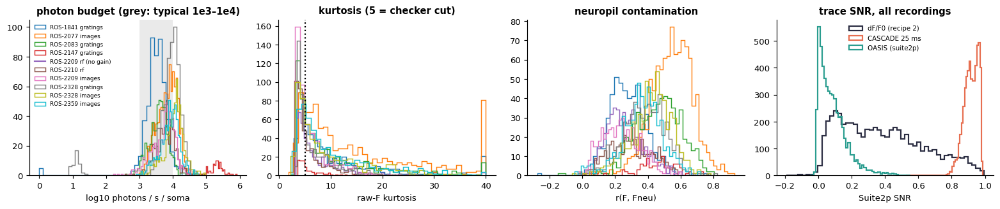

In [7]:
qc = pd.DataFrame((r.Quality.Cell * imaging.MaskClassification.MaskType & 'mask_type="soma"' & REC[["scan_id"]].to_dict("records")).fetch(as_dict=True)).merge(REC[["scan_id", "subject", "paradigm"]], on="scan_id")
tq = pd.DataFrame((r.TraceQuality.Cell * imaging.MaskClassification.MaskType & 'mask_type="soma"' & "fluo_channel=0" & REC[["scan_id"]].to_dict("records")).fetch(as_dict=True)).merge(REC[["scan_id", "subject"]], on="scan_id")
fig, ax = plt.subplots(1, 4, figsize=(15, 3.2))
for (sid, d), c in zip(qc.groupby("scan_id"), plt.cm.tab10(np.arange(10))):
    lab = f"{d.subject.iloc[0]} {d.paradigm.iloc[0]}"
    ph = d.photons_per_s.dropna()
    if len(ph): ax[0].hist(np.log10(ph.clip(1)), 40, histtype="step", color=c, label=lab)
    else: ax[0].plot([], [], color=c, label=lab + " (no gain)")
    ax[1].hist(d["kurtosis"].dropna().clip(0, 40), 40, histtype="step", color=c); ax[2].hist(d.neuropil_r.dropna(), 40, histtype="step", color=c)
ax[0].axvspan(3, 4, color="#ccc", alpha=.4, lw=0); ax[0].set(xlabel="log10 photons / s / soma", title="photon budget (grey: typical 1e3–1e4)"); ax[0].legend(fontsize=6)
ax[1].axvline(5, color="k", ls=":"); ax[1].set(xlabel="raw-F kurtosis", title="kurtosis (5 = checker cut)"); ax[2].set(xlabel="r(F, Fneu)", title="neuropil contamination")
for s in ("dff0_r2", "cascade25", "oasis"):
    ax[3].hist(tq[tq.trace_source == s].snr_s2p, 50, histtype="step", lw=1.5, color=COL[s], label=LBL[s])
ax[3].set(xlabel="Suite2p SNR", title="trace SNR, all recordings"); ax[3].legend(fontsize=7); plt.tight_layout()

## 4. Gallery: every recording

For each recording: a trace segment of its most responsive soma cell (ZETA on OASIS) on all three trace types with
every stimulus marked (gratings: direction label); the PSTH of the most responsive, a median and the least responsive
soma cell with the paradigm's standard window (red / blue: dF/F0 and OASIS; orange: CASCADE where it differs — images read-out 11); in grey: the single natural images shown between the repeated ones; and the most responsive cell's trial raster (sorted by
condition). Titles give animal, date, paradigm, curation and the latency source.

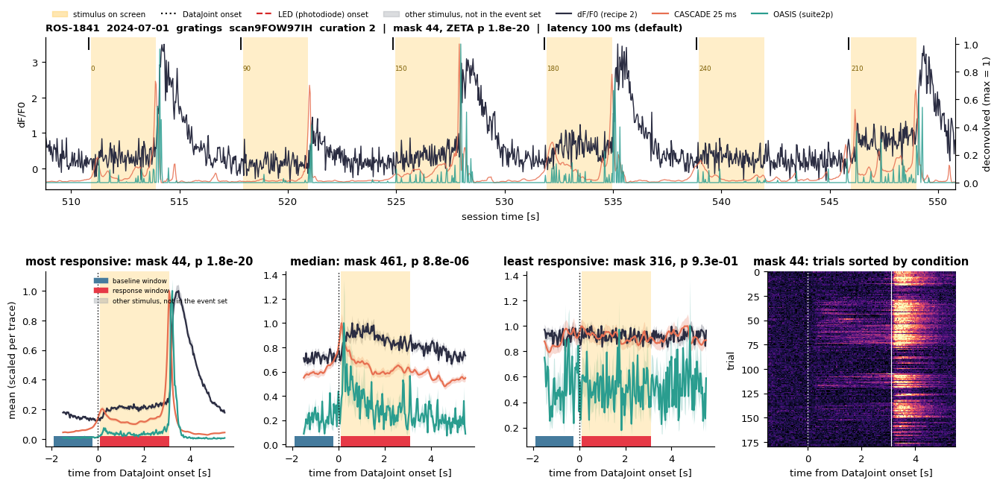

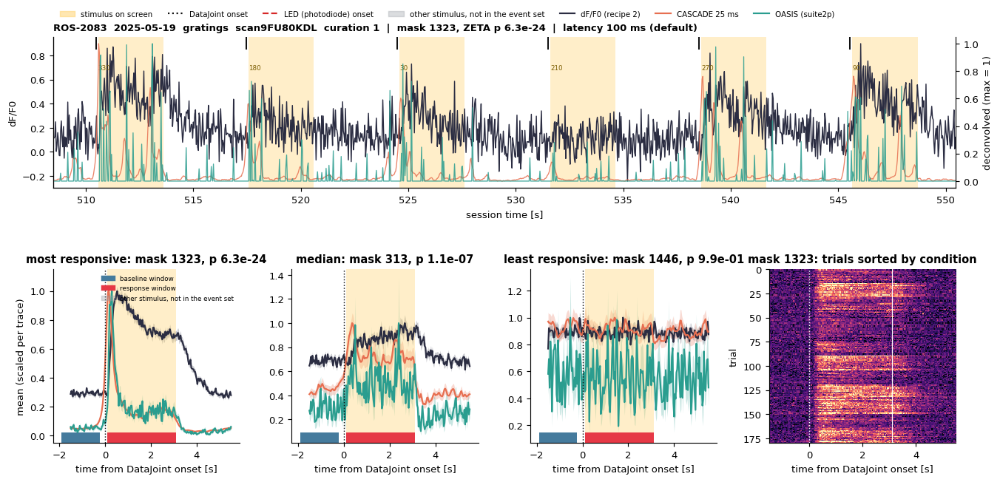

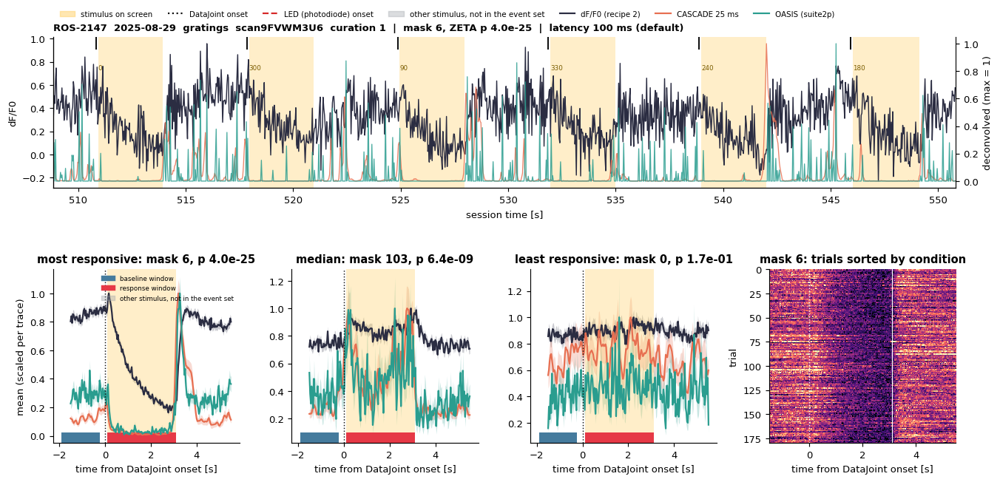

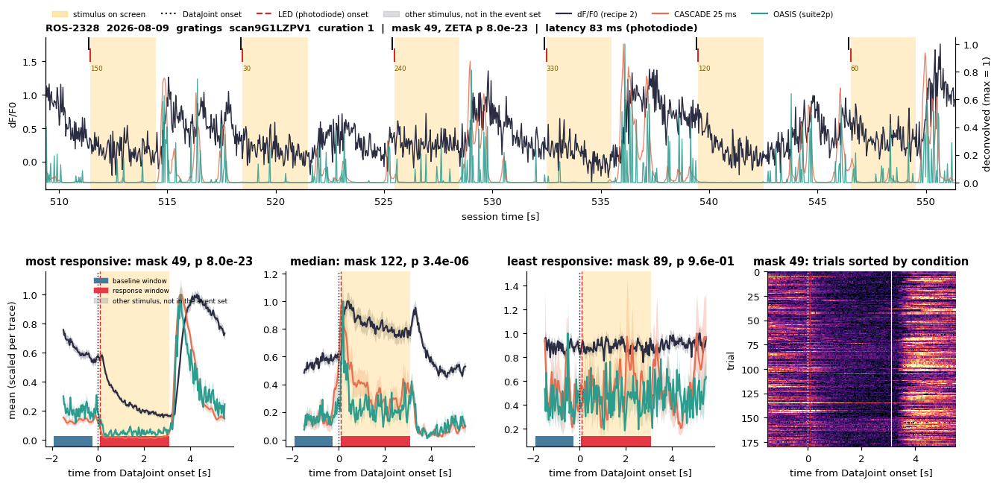

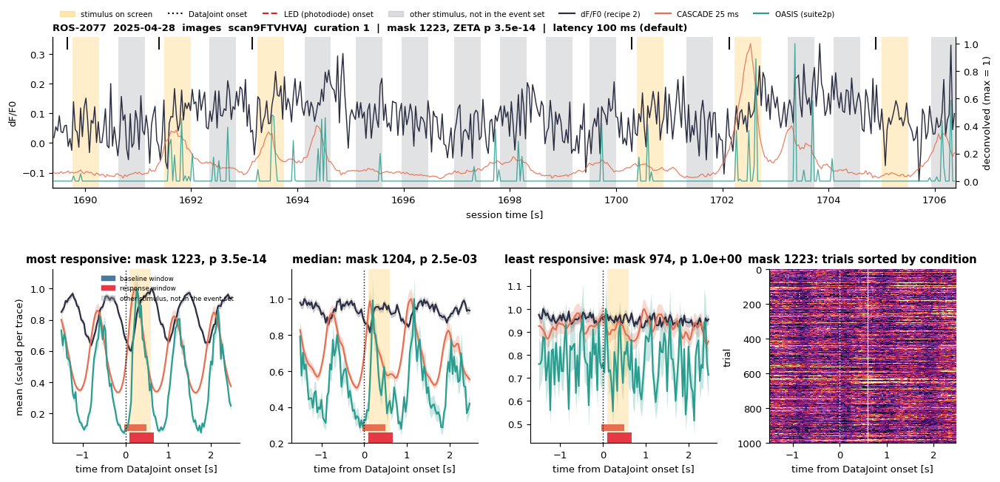

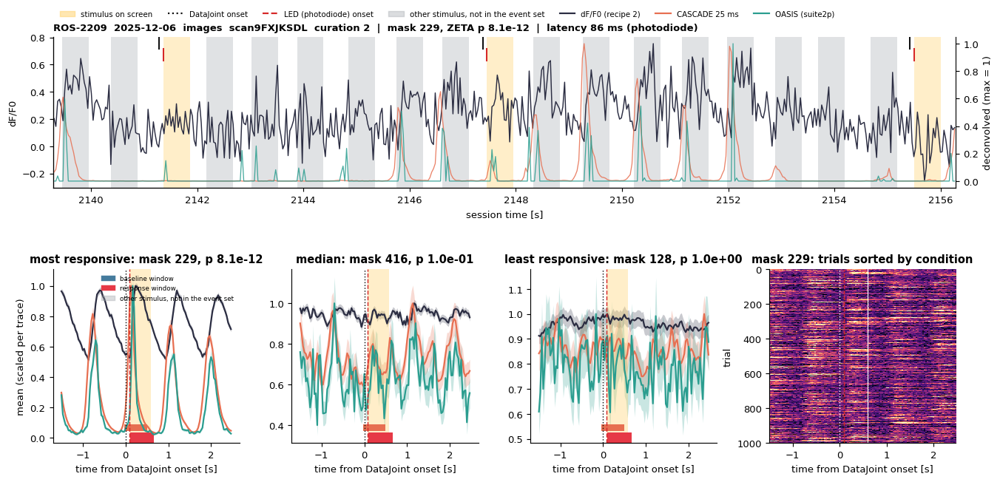

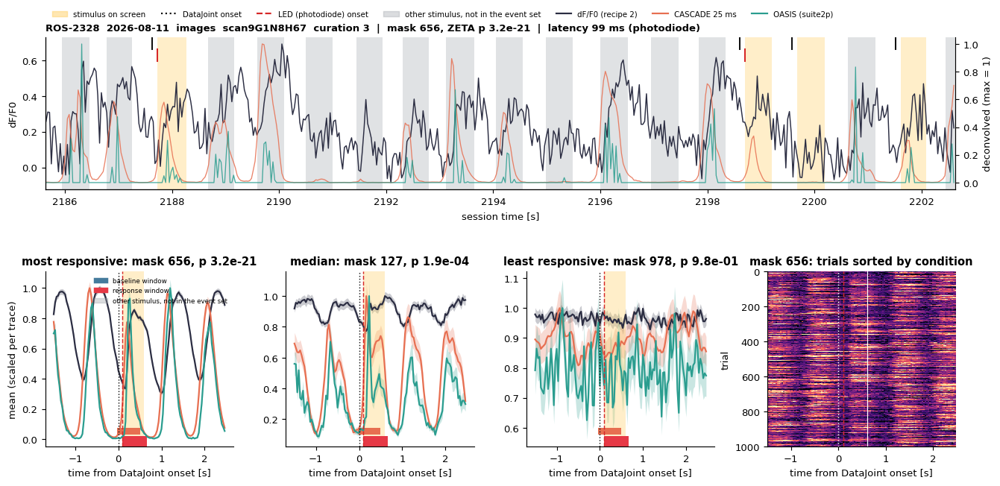

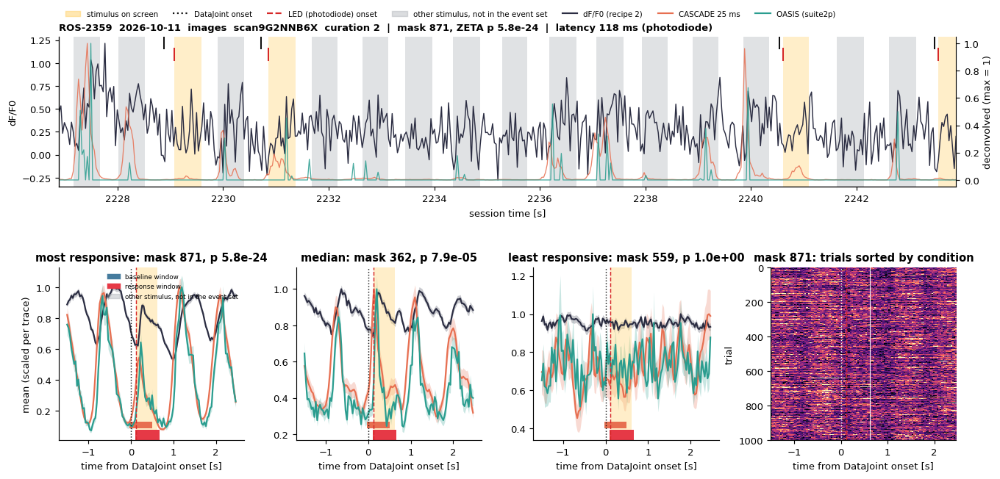

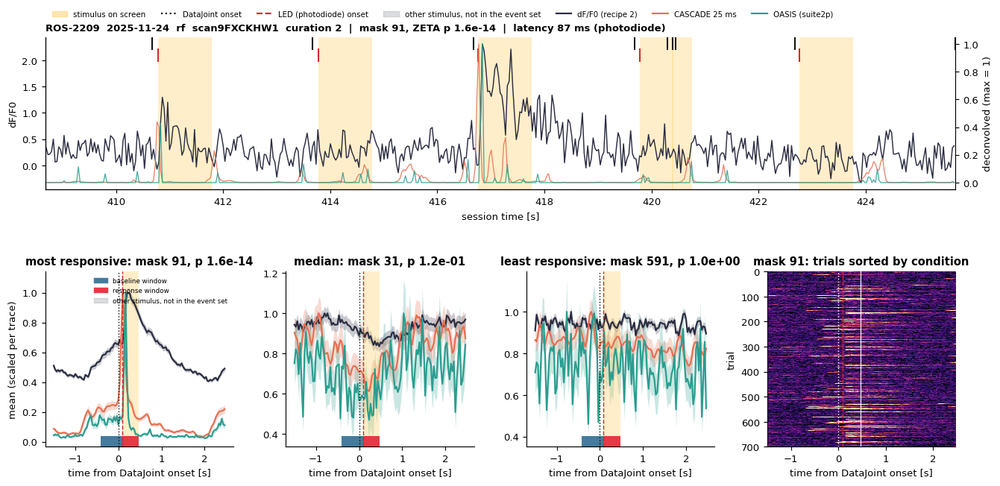

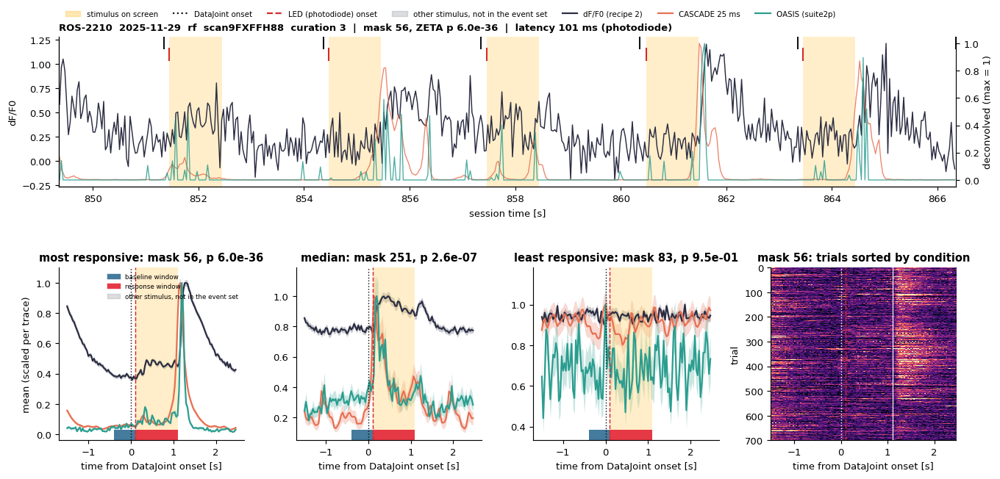

In [8]:
def gallery(row):
    k = key(row); sel = row.selector; tm = timing(k, sel); ft = frame_times(k)
    z = (r.Zeta.Cell * imaging.MaskClassification.MaskType & k & {"event_selector": sel, "trace_source": "oasis", "zeta_idx": 1}
         & 'mask_type="soma"').proj("zeta_p", "latency").fetch(format="frame").reset_index().dropna(subset=["zeta_p"]).sort_values("zeta_p")
    if not len(z): print("no ZETA rows for", row.scan_id); return
    picks = [z.iloc[0], z.iloc[len(z) // 2], z.iloc[-1]]
    ro8 = readout_row(k, sel, "dff0_r2", std(sel, "dff0_r2"))
    roc = readout_row(k, sel, "cascade25", std(sel, "cascade25")) if std(sel, "cascade25") != std(sel, "dff0_r2") else None
    dur = np.nanmedian(tm["t1"] - tm["t0"]); pre, post = (1.5, 2.5) if dur < 1.5 else (1.5, dur + 2.5)
    fig = plt.figure(figsize=(15, 6.8)); gs = GridSpec(2, 4, figure=fig, height_ratios=[1, 1.15], hspace=.5, wspace=.28)
    ax = fig.add_subplot(gs[0, :]); m0 = int(picks[0]["mask"])
    i0 = int(np.argmin(np.abs(tm["t0"] - np.percentile(tm["t0"], 40)))); win = (tm["t0"][i0] - 2, tm["t0"][i0] + (40 if dur > 1.5 else 15))
    X = {s: trace(k, m0, s) for s in ("dff0_r2", "cascade25", "oasis")}; n = min(len(ft), *(len(v) for v in X.values()))
    w_ = (ft[:n] > win[0]) & (ft[:n] < win[1])
    mark_timeline(ax, tm, win, labels=tm["cond"] if row.paradigm == "gratings" else None, others=other_events(k, sel, tm, win))
    ax.plot(ft[:n][w_], X["dff0_r2"][:n][w_], color=COL["dff0_r2"], lw=1); ax2 = ax.twinx()
    for s in ("cascade25", "oasis"):
        v = X[s][:n][w_]; ax2.plot(ft[:n][w_], v / (np.nanmax(v) or 1), color=COL[s], lw=.9, alpha=.85)
    ax.set(ylabel="dF/F0", xlim=win, xlabel="session time [s]"); ax2.set_ylabel("deconvolved (max = 1)"); ax2.spines["right"].set_visible(True)
    ax.set_title(f"{row.subject}  {row.date}  {row.paradigm}  {row.scan_id}  curation {row.curation_id}  |  mask {m0}, ZETA p {picks[0].zeta_p:.1e}  |  "
                 f"latency {tm['lat']*1e3:.0f} ms ({'photodiode' if tm['has_diode'] else 'default'})", loc="left", fontsize=9)
    handles = LEGEND[:3] + LEGEND[5:] + [Line2D([], [], color=COL[s], label=LBL[s]) for s in ("dff0_r2", "cascade25", "oasis")]
    ax.legend(handles=handles, fontsize=7, ncol=7, loc="upper left", bbox_to_anchor=(0, 1.22))
    for j, (pk, name) in enumerate(zip(picks, ("most responsive", "median", "least responsive"))):
        a = fig.add_subplot(gs[1, j]); m = int(pk["mask"])
        for s in ("dff0_r2", "cascade25", "oasis"):
            g, M = peri(trace(k, m, s), ft, tm["t0"], pre, post); psth(a, g, M, COL[s], scale=True)
        mark_psth(a, tm, ro8, roc); a.set(title=f"{name}: mask {m}, p {pk.zeta_p:.1e}", xlabel="time from DataJoint onset [s]")
        if j == 0: a.set_ylabel("mean (scaled per trace)"); a.legend(handles=LEGEND[3:], fontsize=6, loc="upper right")
    a = fig.add_subplot(gs[1, 3]); g, M = peri(trace(k, m0, "dff0_r2"), ft, tm["t0"], pre, post)
    order = np.argsort(tm["cond"], kind="stable")
    a.imshow(M[order], aspect="auto", cmap="magma", extent=(g[0], g[-1], len(M), 0), vmin=np.nanpercentile(M, 1), vmax=np.nanpercentile(M, 99), interpolation="nearest")
    a.axvline(0, color="w", ls=":", lw=1)
    if tm["has_diode"]: a.axvline(np.nanmedian(tm["led_on"] - tm["t0"]), color=COL["led"], ls="--", lw=1)
    a.axvline(np.nanmedian(tm["screen_off"] - tm["t0"]), color="w", lw=.8)
    a.set(title=f"mask {m0}: trials sorted by condition", xlabel="time from DataJoint onset [s]", ylabel="trial")
    plt.show()

for _, row in REC.iterrows():
    try:
        gallery(row)
    except Exception as e:
        print("skipped", row.scan_id, repr(e)[:200])

## 5. Read-outs: explicit windows, stored edges

Each `ReadoutParamSet` row gives the response window and the baseline window an explicit start and end (stimulus
onset or offset + seconds or frames) on screen or DataJoint time. Below: one grating and one image cell, every read-out
of its recording drawn from the edges `Readout` stored.

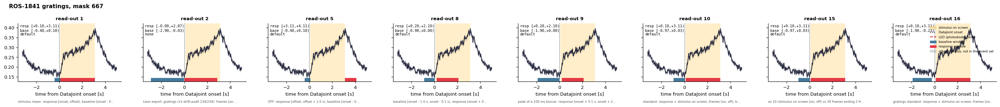

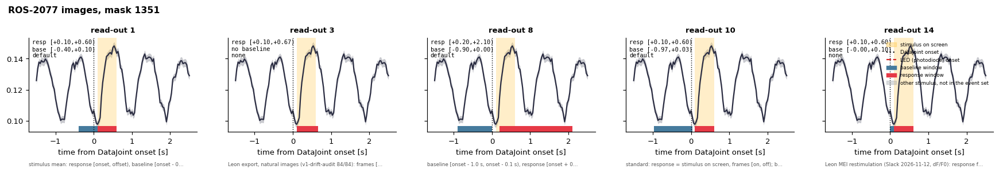

In [9]:
for par in ("gratings", "images"):
    row = REC[REC.paradigm == par].iloc[0]; k = key(row); tm = timing(k, row.selector); ft = frame_times(k)
    ros = sorted((r.Readout & k & {"event_selector": row.selector, "trace_source": "dff0_r2"}).fetch(as_dict=True), key=lambda e: e["readout_idx"])
    best = int((r.Readout.Cell * imaging.MaskClassification.MaskType & k & {"event_selector": row.selector, "trace_source": "dff0_r2", "readout_idx": ros[0]["readout_idx"]}
                & 'mask_type="soma"').proj("effect_d").fetch(format="frame").reset_index().sort_values("effect_d", ascending=False).iloc[0]["mask"])
    dur = np.nanmedian(tm["t1"] - tm["t0"]); pre = max([1.5] + [-(e["base_start_s"] or 0) + .3 for e in ros])   # show every whole window
    g, M = peri(trace(k, best, "dff0_r2"), ft, tm["t0"], pre, dur + 2)
    fig, ax = plt.subplots(1, len(ros), figsize=(3.4 * len(ros), 3.2), sharey=True)
    for a, e in zip(np.atleast_1d(ax), ros):
        psth(a, g, M, COL["dff0_r2"]); mark_psth(a, tm, e)
        desc = (r.ReadoutParamSet & {"readout_idx": e["readout_idx"]}).fetch1("readout_desc")
        a.set_title(f"read-out {e['readout_idx']}", fontsize=9); a.set_xlabel("time from DataJoint onset [s]")
        a.text(.02, .98, f"resp [{e['resp_start_s']:+.2f},{e['resp_stop_s']:+.2f})" + (f"\nbase [{e['base_start_s']:+.2f},{e['base_stop_s']:+.2f})" if e["base_stop_s"] is not None else "\nno baseline")
               + f"\n{e['latency_source']}", transform=a.transAxes, va="top", fontsize=7, family="monospace")
        a.text(.0, -.36, desc[:60] + ("…" if len(desc) > 60 else ""), transform=a.transAxes, fontsize=6, color="#555")
    np.atleast_1d(ax)[-1].legend(handles=LEGEND, fontsize=6, loc="upper right"); fig.suptitle(f"{row.subject} {row.paradigm}, mask {best}", x=.01, ha="left", fontweight="bold")
    plt.tight_layout(); plt.show()

## 6. Calibration: real onsets vs random onsets ("no stimulus")

The `*_random` selectors move every onset of a recording to a seeded random time; ZETA keeps the real events' window
(as the audit's t73 null). With nothing time-locked, the fraction of soma cells with p < 0.05 should be ≈ 5 %.
Read-outs without a baseline (3, 7: Leon's image window, CASCADE trees) are not tests and are left out — for images the
audit decides responsiveness by ZETA and reliability by the oracle.

**What the pilot shows.** Calibrated (≈ 5 %): ZETA on images; Leon's grating window (read-out 2, 2–3 %); read-outs 1,
8 and 9 (4–8 %). ZETA on gratings gives 12–14 %, as the audit's own null (8–16 %). Read-out 5 (OFF window, 1 s after
offset against 0.5 s before onset) stays at 10–13 % on the deconvolved traces — prefer ZETA or read-out 2 for calls.
How the read-outs are built so that they hold: the baseline is read with the same measure as the response; any
measure other than the mean needs equally long windows (`base_length = 'match_response'`; `Readout` refuses otherwise);
the test is a paired t-test (Wilcoxon on windows of different length is biased on sparse spike traces: 15–45 % before
this was fixed); read-outs without a baseline store no p-value. On images, read-out 8 calls ≈ 4 % with real onsets as
well: the baseline window holds the previous single image's response — use Leon's window (3) with ZETA and the oracle.

In [10]:
somas = pd.DataFrame((imaging.MaskClassification.MaskType & 'mask_type="soma"' & REC[["scan_id"]].to_dict("records")).fetch("scan_id", "curation_id", "mask", as_dict=True))
rp = pd.DataFrame(((r.Readout & "base_stop_s IS NOT NULL").proj() * r.Readout.Cell & "fluo_channel=0").proj("resp_p").fetch(as_dict=True)).merge(somas, on=["scan_id", "curation_id", "mask"])
rp["kind"] = np.where(rp.event_selector.str.endswith("_random"), "random onsets", "real onsets"); rp["paradigm"] = rp.event_selector.str.replace("_random", "")
rr = rp[rp.scan_id.isin(rp[rp.kind == "random onsets"].scan_id.unique())]
tab = rr.groupby(["paradigm", "readout_idx", "trace_source", "kind"]).resp_p.apply(lambda p: np.mean(p < .05)).unstack("kind").mul(100).round(1)
zp = pd.DataFrame((r.Zeta.Cell & "zeta_idx=1").proj("zeta_p").fetch(as_dict=True))
zp["kind"] = np.where(zp.event_selector.str.endswith("_random"), "random onsets", "real onsets"); zp["paradigm"] = zp.event_selector.str.replace("_random", "")
zp = zp[zp.scan_id.isin(zp[zp.kind == "random onsets"].scan_id.unique())]
zt = zp.groupby(["paradigm", "trace_source", "kind"]).zeta_p.apply(lambda p: np.mean(p < .05)).unstack("kind").mul(100).round(1)
zt.index = pd.MultiIndex.from_tuples([(a, "ZETA", b) for a, b in zt.index], names=tab.index.names)
pd.concat([tab, zt]).sort_index().style.background_gradient(subset=["random onsets"], cmap="Reds", vmin=0, vmax=30).format("{:.1f} %").set_caption("% of soma cells with p < 0.05")

## 7. Agreement with the v1-drift-audit

* **ZETA** vs the audit's own run (`artefacts/t73`) for every pilot recording it covered: same traces, events, window.
* **Grating tuning** vs the audit's `g1` table (OASIS, the export stimulus window = read-out 2, θ = (90 − label),
  unrectified = tuning setting 2): OSI = 1 − CirVar, DSI = 1 − DirCirVar, preferred angles, `p_tuned`, `p_resp`.

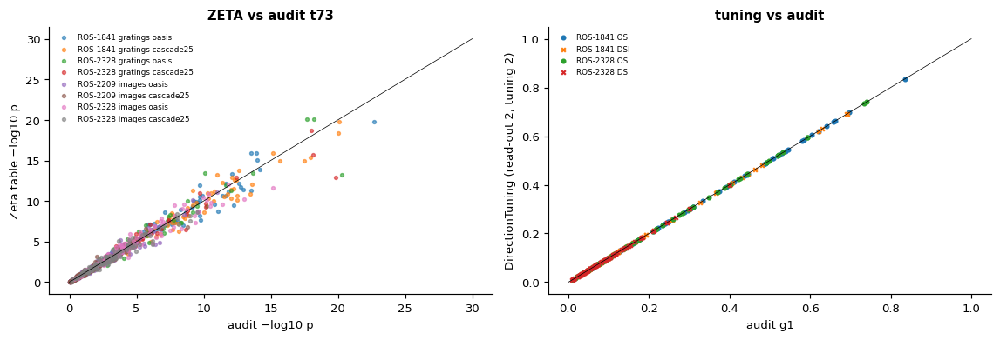

,recording,signal,cells,rank_r,audit_p05,ours_p05,calls_differ
0,ROS-1841 gratings,oasis,63,0.962,62,62,0
1,ROS-1841 gratings,cascade25,63,0.955,63,63,0
2,ROS-2328 gratings,oasis,48,0.974,46,46,0
3,ROS-2328 gratings,cascade25,48,0.985,44,45,1
4,ROS-2209 images,oasis,248,0.991,114,113,11
5,ROS-2209 images,cascade25,248,0.989,92,90,10
6,ROS-2328 images,oasis,107,0.981,100,101,1
7,ROS-2328 images,cascade25,107,0.975,88,88,6


,recording,cells,max_abs_osi,max_abs_dsi,max_po_deg,tuned_calls_agree,resp_calls_agree
0,ROS-1841 gratings,63,0.000005,0.000005,0.005,63/63,63/63
1,ROS-2328 gratings,79,0.000005,0.000005,0.005,79/79,79/79


In [11]:
from scipy.stats import spearmanr
T73 = os.path.expanduser("~/resp_pilot/t73/"); out = []
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for _, row in REC.iterrows():
    par = {"gratings": "gratings", "images": "images"}.get(row.paradigm); f = f"{T73}zeta_{par}_{row.scan_id}.tsv"
    if not par or not os.path.exists(f): continue
    A = pd.read_csv(f, sep="\t")
    for src in ("oasis", "cascade25"):
        z = (r.Zeta.Cell & key(row) & {"event_selector": row.selector, "trace_source": src, "zeta_idx": 1}).proj("zeta_p").fetch(format="frame").reset_index()
        m = A[A.signal == src][["mask", "zeta_p"]].merge(z, on="mask", suffixes=("_audit", ""))
        if not len(m): continue
        ax[0].scatter(-np.log10(m.zeta_p_audit.clip(1e-30)), -np.log10(m.zeta_p.clip(1e-30)), s=7, alpha=.6, label=f"{row.subject} {par} {src}")
        out.append(dict(recording=f"{row.subject} {par}", signal=src, cells=len(m), rank_r=round(spearmanr(m.zeta_p_audit, m.zeta_p)[0], 3),
                        audit_p05=int((m.zeta_p_audit < .05).sum()), ours_p05=int((m.zeta_p < .05).sum()),
                        calls_differ=int(((m.zeta_p_audit < .05) != (m.zeta_p < .05)).sum())))
ax[0].plot([0, 30], [0, 30], color="k", lw=.5); ax[0].set(xlabel="audit −log10 p", ylabel="Zeta table −log10 p", title="ZETA vs audit t73"); ax[0].legend(fontsize=6)
E = os.path.expanduser("~/v1-drift-audit/data/export/rose_export_v1/")
g1 = pd.read_csv(T73 + "g1_cells_grat_oasis_stim.csv"); res = []
wr = lambda d, P: np.abs((d + P / 2) % P - P / 2)
for _, row in REC[REC.paradigm == "gratings"].iterrows():
    for bf in (E + f"gratings/{row.subject}_MG_behavior_synced.npz", E + f"gratings/{row.subject}_MG_behavior_imgmatched_synced.npz"):
        if os.path.exists(bf): break
    if not os.path.exists(bf) or not (g1.animal == row.subject).any(): continue
    zb = np.load(bf, allow_pickle=True); scans = [str(s) for s in zb["scans"]]
    if row.scan_id not in scans: continue
    s_ = scans.index(row.scan_id); om = {}
    if "match_grating_mask" in zb.files:          # image-matched export: cell c of this session is mask match_grating_mask[s, c] (-1 = absent)
        om = {c: int(m_) for c, m_ in enumerate(zb["match_grating_mask"][s_]) if m_ >= 0}
    else:                                         # CellReg export: cell -> mask from the pairwise match table
        ms = pd.read_csv(E + f"match_scores/gratings/{row.subject}_match_scores.tsv", sep="\t")
        for cell, sa, sb, ma, mb in zip(ms.cell, ms.session_a, ms.session_b, ms.mask_a, ms.mask_b):
            for q_, m_ in ((sa, ma), (sb, mb)):
                if q_ == s_: om[int(cell)] = int(m_)
    a1 = g1[(g1.animal == row.subject) & (g1.session == s_)].copy(); a1["mask"] = a1.cell.map(om)
    ours = (r.DirectionTuning.Cell * r.Readout.Cell.proj("resp_p", "cond_kw_p") & key(row) & {"event_selector": "gratings", "trace_source": "oasis",
            "readout_idx": 2, "tuning_idx": 2}).proj("ori_vec", "dir_vec", "pref_ori_vec", "ori_kw_p", "resp_p", "cond_kw_p").fetch(format="frame").reset_index()
    mm = a1.merge(ours, on="mask")
    if not len(mm): continue
    mm["p_resp_ours"] = np.minimum(mm.resp_p, mm.cond_kw_p)
    ax[1].scatter(mm.osi, mm.ori_vec, s=10, label=f"{row.subject} OSI"); ax[1].scatter(mm.dsi, mm.dir_vec, s=10, marker="x", label=f"{row.subject} DSI")
    res.append(dict(recording=f"{row.subject} gratings", cells=len(mm), max_abs_osi=np.abs(mm.osi - mm.ori_vec).max(), max_abs_dsi=np.abs(mm.dsi - mm.dir_vec).max(),
                    max_po_deg=wr(mm.po - mm.pref_ori_vec, 180).max(), tuned_calls_agree=f"{int(((mm.p_tuned < .01) == (mm.ori_kw_p < .01)).sum())}/{len(mm)}",
                    resp_calls_agree=f"{int(((mm.p_resp < .01) == (mm.p_resp_ours < .01)).sum())}/{len(mm)}"))
ax[1].plot([0, 1], [0, 1], color="k", lw=.5); ax[1].set(xlabel="audit g1", ylabel="DirectionTuning (read-out 2, tuning 2)", title="tuning vs audit"); ax[1].legend(fontsize=6)
plt.tight_layout(); plt.show()
display(pd.DataFrame(out)); display(pd.DataFrame(res))

## 8. Grating tuning across recordings

`DirectionTuning` on the standard grating window (read-out 16, raw trial values) and CASCADE, tuning setting 1 (θ = (90 − label),
Mazurek et al. 2014 indices on rectified condition means). Section 7 checks the audit's own convention (read-out 2, OASIS). Per recording: a direction-selective, an orientation-selective
and an untuned soma cell — per-direction dF/F0 PSTHs (grey: single trials) with read-out 16's windows, and the CASCADE read-out 16 tuning curve (polar, the values the indices use) with its double-Gaussian fit.

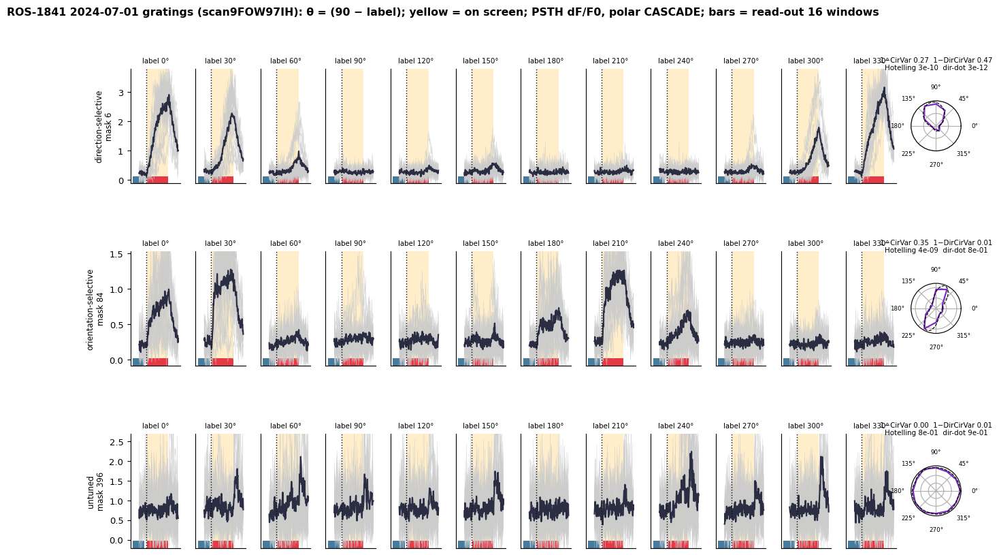

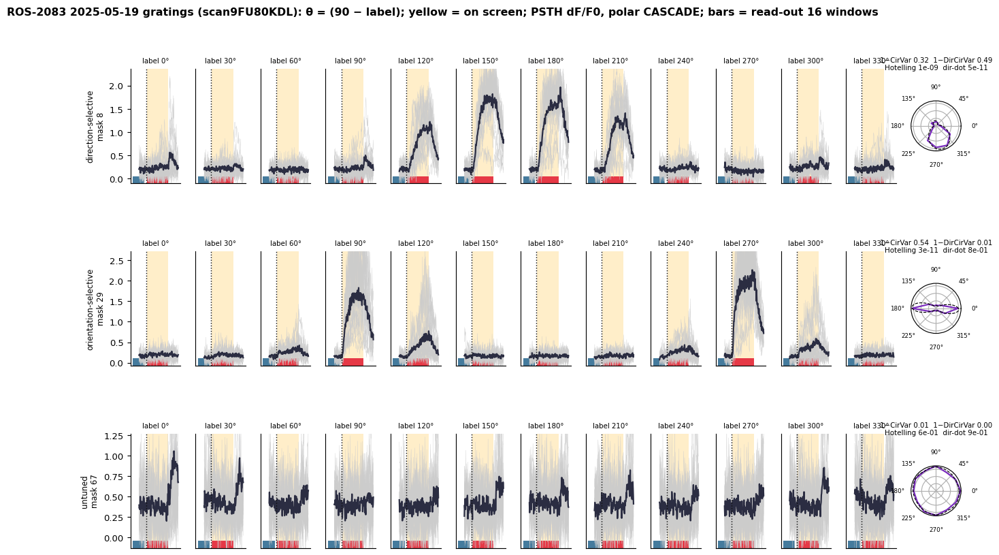

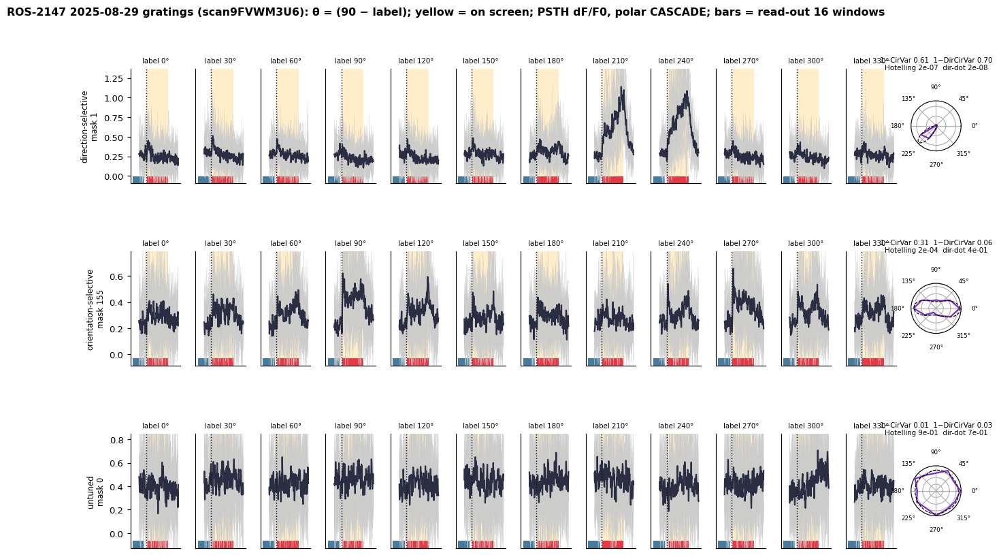

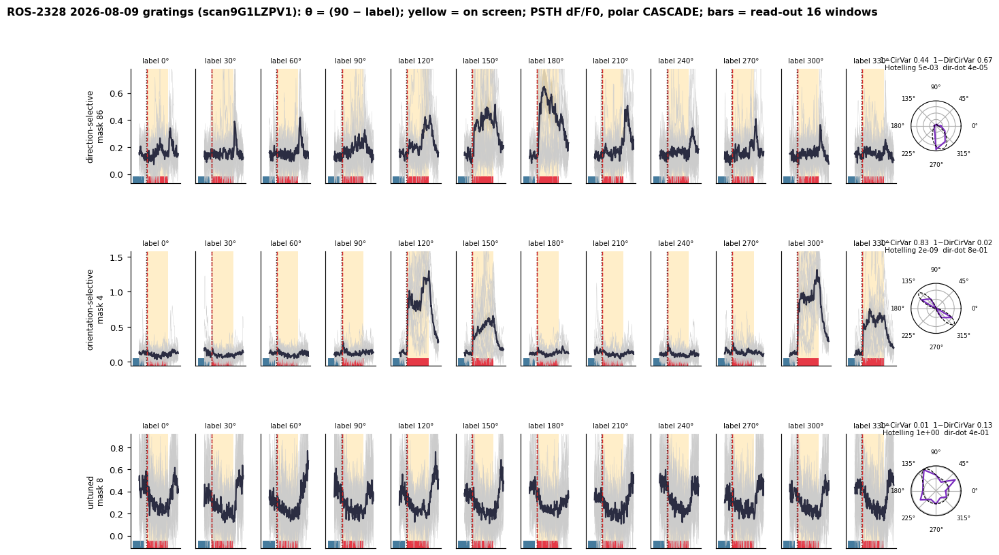

In [12]:
def tuning_examples(row):
    k = key(row); tm = timing(k, "gratings"); ft = frame_times(k); ro1 = readout_row(k, "gratings", TUNE["trace_source"], TUNE["readout_idx"])
    dt = (r.DirectionTuning.Cell * imaging.MaskClassification.MaskType * (r.TraceQuality.Cell & {"trace_source": "dff0_r2"}).proj(snr="snr_s2p", ts="trace_source")
          & k & {"event_selector": "gratings", **TUNE} & 'mask_type="soma"').fetch(format="frame").reset_index()
    good = (dt.r_pref > 0) & (dt.snr > dt.snr.median())
    ds = dt[good & (dt.hotelling_p < .01) & (dt.dir_dot_p < .01) & dt.dsi.between(0, 1)].sort_values("dir_vec", ascending=False)
    os_ = dt[good & (dt.hotelling_p < .01) & (dt.dir_dot_p > .3) & dt.osi.between(0, 1)].sort_values("ori_vec", ascending=False)
    un = dt[good & (dt.hotelling_p > .5) & (dt.dir_dot_p > .3)].sort_values("ori_vec")
    ex = [(n_, d_.iloc[0]) for n_, d_ in (("direction-selective", ds), ("orientation-selective", os_), ("untuned", un)) if len(d_)]
    if not ex: print("no examples", row.scan_id); return
    labels = np.array(sorted({float(c) for c in tm["cond"]})); dur = np.nanmedian(tm["t1"] - tm["t0"])
    fig = plt.figure(figsize=(15, 2.7 * len(ex) + .6)); gs = GridSpec(len(ex), len(labels) + 1, figure=fig, hspace=.6, wspace=.3)
    for i, (name, rw) in enumerate(ex):
        m = int(rw["mask"]); g, M = peri(trace(k, m, "dff0_r2"), ft, tm["t0"], 1, dur + 1.5)     # PSTH on dF/F0 (readable); tuning from OASIS
        tr = np.asarray((r.Readout.Cell & k & {"event_selector": "gratings", "trace_source": TUNE["trace_source"], "readout_idx": TUNE["readout_idx"], "mask": m, "fluo_channel": 0}).fetch1("trial_resp"), float)
        ymax = np.nanmax([np.nanmean(M[tm["cond"] == f"{l:g}"], 0).max() for l in labels]) * 1.2
        for j, l in enumerate(labels):
            a = fig.add_subplot(gs[i, j]); Mi = M[tm["cond"] == f"{l:g}"]
            a.plot(g, Mi.T, color="#ccc", lw=.25); psth(a, g, Mi, COL["dff0_r2"]); mark_psth(a, tm, ro1)
            a.set_ylim(np.nanpercentile(M, 1), ymax); a.set_xticks([]); a.set_title(f"label {l:g}°", fontsize=7, fontweight="normal")
            if j: a.set_yticks([])
            else: a.set_ylabel(f"{name}\nmask {m}", fontsize=8)
        a = fig.add_subplot(gs[i, -1], projection="polar")
        th = (90 - labels) % 360; mean = np.array([np.nanmean(tr[tm["cond"] == f"{l:g}"]) for l in labels]); o = np.argsort(th)
        a.plot(np.deg2rad(np.r_[th[o], th[o][:1]]), np.r_[mean[o], mean[o][:1]], color=COL["accent"], lw=1.5)
        if np.isfinite(rw.fit_pref_dir):
            tt = np.linspace(0, 360, 361); dd = lambda v: (v + 180) % 360 - 180
            fit = rw.fit_c + rw.fit_rp * np.exp(-dd(tt - rw.fit_pref_dir) ** 2 / (2 * rw.fit_sigma ** 2)) + rw.fit_rn * np.exp(-dd(tt - rw.fit_pref_dir + 180) ** 2 / (2 * rw.fit_sigma ** 2))
            a.plot(np.deg2rad(tt), fit, color="k", ls="--", lw=.8)
        a.set_yticklabels([]); a.tick_params(labelsize=6)
        a.set_title(f"1−CirVar {rw.ori_vec:.2f}  1−DirCirVar {rw.dir_vec:.2f}\nHotelling {rw.hotelling_p:.0e}  dir-dot {rw.dir_dot_p:.0e}", fontsize=7, fontweight="normal", pad=14)
    fig.suptitle(f"{row.subject} {row.date} gratings ({row.scan_id}): θ = (90 − label); yellow = on screen; PSTH dF/F0, polar CASCADE; bars = read-out 16 windows", x=.01, ha="left", fontweight="bold"); plt.show()

for _, row in REC[REC.paradigm == "gratings"].iterrows():
    try: tuning_examples(row)
    except Exception as e: print("skipped", row.scan_id, repr(e)[:200])

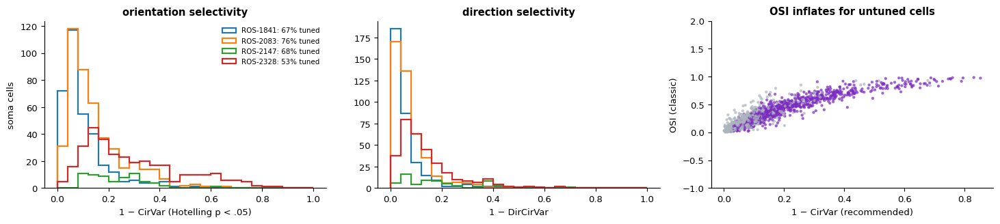

In [13]:
dt = pd.DataFrame((r.DirectionTuning.Cell & TUNE).fetch(as_dict=True)).merge(somas, on=["scan_id", "curation_id", "mask"]).merge(REC[["scan_id", "subject"]], on="scan_id")
fig, ax = plt.subplots(1, 3, figsize=(14, 3.2))
for (sid, d), c in zip(dt.groupby("scan_id"), plt.cm.tab10(np.arange(10))):
    sig = d.hotelling_p < .05
    ax[0].hist(d.ori_vec[sig], np.linspace(0, 1, 26), histtype="step", lw=1.5, color=c, label=f"{d.subject.iloc[0]}: {sig.mean():.0%} tuned")
    ax[1].hist(d.dir_vec[sig], np.linspace(0, 1, 26), histtype="step", lw=1.5, color=c)
ax[0].set(xlabel="1 − CirVar (Hotelling p < .05)", ylabel="soma cells", title="orientation selectivity"); ax[0].legend(fontsize=7)
ax[1].set(xlabel="1 − DirCirVar", title="direction selectivity")
ax[2].scatter(dt.ori_vec, dt.osi, s=4, c=np.where(dt.hotelling_p < .05, COL["accent"], COL["null"]), alpha=.6); ax[2].set_ylim(-1, 2)
ax[2].set(xlabel="1 − CirVar (recommended)", ylabel="OSI (classic)", title="OSI inflates for untuned cells"); plt.tight_layout()

## 9. Natural images: reliability on the repeated set

The standard image windows (OASIS and dF/F0: read-out 3, Leon's frames [on + 3, on + 3 + n); CASCADE: read-out 11, frames [on − 1, on + 15)) on the images shown ≥ 5 times: leave-one-repeat-out
**oracle** per cell, per recording and trace type; below: the most reliable cell of each recording (image × repeat).

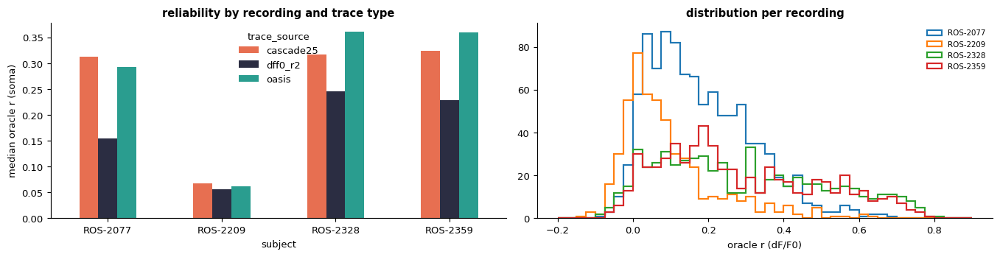

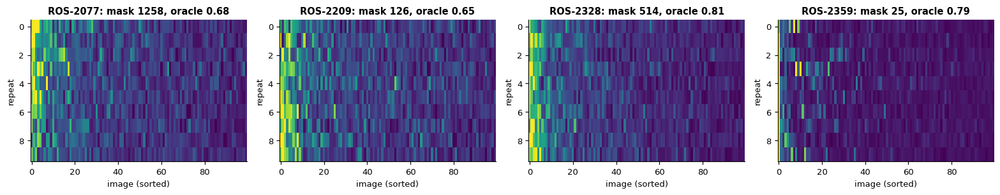

In [14]:
IMG_STD = [{"trace_source": "oasis", "readout_idx": 3}, {"trace_source": "dff0_r2", "readout_idx": 3}, {"trace_source": "cascade25", "readout_idx": 11}]
ro = pd.DataFrame((r.Readout.Cell & {"event_selector": "nat_images_repeated"} & IMG_STD).proj("oracle_r", "response_snr").fetch(as_dict=True)).merge(somas, on=["scan_id", "curation_id", "mask"]).merge(REC[["scan_id", "subject"]], on="scan_id")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
summ = ro.groupby(["subject", "trace_source"]).oracle_r.median().unstack()
summ.plot.bar(ax=ax[0], color=[COL[c] for c in summ.columns]); ax[0].set(ylabel="median oracle r (soma)", title="reliability by recording and trace type"); ax[0].tick_params(axis="x", rotation=0)
for (sid, d), c in zip(ro[ro.trace_source == "dff0_r2"].groupby("scan_id"), plt.cm.tab10(np.arange(10))):
    ax[1].hist(d.oracle_r.dropna(), np.linspace(-.2, .9, 45), histtype="step", lw=1.5, color=c, label=d.subject.iloc[0])
ax[1].set(xlabel="oracle r (dF/F0)", title="distribution per recording"); ax[1].legend(fontsize=7); plt.tight_layout(); plt.show()
imgrec = REC[REC.paradigm == "images"]
fig, axs = plt.subplots(1, len(imgrec), figsize=(15, 3))
for a, (_, row) in zip(np.atleast_1d(axs), imgrec.iterrows()):
    k = key(row); tm = timing(k, "nat_images_repeated"); d = ro[(ro.scan_id == row.scan_id) & (ro.trace_source == "dff0_r2")].dropna(subset=["oracle_r"])
    if not len(d): a.axis("off"); continue
    b = d.sort_values("oracle_r", ascending=False).iloc[0]
    tr = np.asarray((r.Readout.Cell & k & {"event_selector": "nat_images_repeated", "trace_source": "dff0_r2", "readout_idx": 3, "mask": int(b["mask"]), "fluo_channel": 0}).fetch1("trial_resp"), float)
    imgs = np.unique(tm["cond"]); kmin = min((tm["cond"] == i).sum() for i in imgs)
    Rm = np.vstack([tr[tm["cond"] == i][:kmin] for i in imgs]); o = np.argsort(np.nanmean(Rm, 1))[::-1]
    a.imshow(Rm[o].T, aspect="auto", cmap="viridis", vmin=np.nanpercentile(Rm, 1), vmax=np.nanpercentile(Rm, 99), interpolation="nearest")
    a.set(title=f"{row.subject}: mask {int(b['mask'])}, oracle {b.oracle_r:.2f}", xlabel="image (sorted)", ylabel="repeat")
plt.tight_layout()

### Image windows compared

Every image read-out of the pilot side by side: Leon's OASIS window (3), the audit's CASCADE consensus (11), the Slack
start rule for CASCADE (12: start 0, the common default; 13: start +1, GCaMP8; 11 is the GCaMP6 start −1), the CASCADE
'opt' trees (7) and Leon's MEI restimulation window (14: [on + 3, off + 3) minus [on, on + 3)). Median leave-one-repeat-out
oracle over soma cells per recording; read-out 14 is also a test (fraction p < 0.05, real vs random onsets).

In [15]:
W = {3: "Leon [+3, +3+n)", 7: "opt [+1, +15)", 11: "consensus [-1, +15)", 12: "Slack 0 [0, +16)", 13: "Slack gc8 [+1, +17)", 14: "MEI [+3, off+3) - [0, +3)"}
q = (r.Readout.Cell & 'event_selector LIKE "nat_images_repeated%%"' & [{"readout_idx": i} for i in W] & "fluo_channel = 0").proj("oracle_r", "resp_p")
d = pd.DataFrame(q.fetch(as_dict=True)).merge(somas, on=["scan_id", "curation_id", "mask"]).merge(REC[["scan_id", "subject"]], on="scan_id")
real = d[~d.event_selector.str.endswith("_random")]
tab = real.groupby(["readout_idx", "trace_source"]).oracle_r.median().unstack("trace_source").round(3)
tab.index = [f"{i}: {W[i]}" for i in tab.index]
display(tab.style.background_gradient(axis=None, cmap="Greens").format("{:.3f}", na_rep="").set_caption("median oracle r, soma cells, all image recordings"))
per = real.groupby(["subject", "readout_idx", "trace_source"]).oracle_r.median().unstack(["trace_source", "readout_idx"]).round(3)
display(per)
t14 = d[d.readout_idx == 14].assign(kind=lambda x: np.where(x.event_selector.str.endswith("_random"), "random onsets", "real onsets"))
t14 = t14[t14.scan_id.isin(t14[t14.kind == "random onsets"].scan_id)]
display(t14.groupby(["trace_source", "kind"]).resp_p.apply(lambda p: f"{np.mean(p < .05):.1%}").unstack("kind"))

trace_source,cascade25,dff0_r2,oasis
"3: Leon [+3, +3+n)",0.263,0.162,0.279
"7: opt [+1, +15)",0.265,,
"11: consensus [-1, +15)",0.260,,
"12: Slack 0 [0, +16)",0.264,,
"13: Slack gc8 [+1, +17)",0.266,,
"14: MEI [+3, off+3) - [0, +3)",0.100,0.134,0.111


trace_source cascade25 dff0_r2  oasis cascade25                              \
readout_idx         3       3      3         7      11     12     13     14   
subject                                                                       
ROS-2077         0.289   0.154  0.292     0.310  0.313  0.310  0.307  0.080   
ROS-2209         0.054   0.056  0.062     0.071  0.068  0.069  0.066  0.024   
ROS-2328         0.330   0.246  0.361     0.327  0.317  0.324  0.328  0.238   
ROS-2359         0.342   0.229  0.360     0.335  0.324  0.330  0.335  0.225   

trace_source dff0_r2  oasis  
readout_idx       14     14  
subject                      
ROS-2077       0.140  0.141  
ROS-2209       0.046  0.023  
ROS-2328       0.196  0.172  
ROS-2359       0.175  0.174

kind,random onsets,real onsets
trace_source,,
cascade25,6.6%,37.2%
dff0_r2,4.1%,48.7%
oasis,4.3%,39.8%


## 10. Receptive fields

Checkerboard selector labels = patch `azimuth|elevation`; the positions form a cross (azimuth sweep at one
elevation, elevation sweep at one azimuth), so each cell has two 1D profiles from `Readout.Condition` (read-out 1,
mean ± SEM).

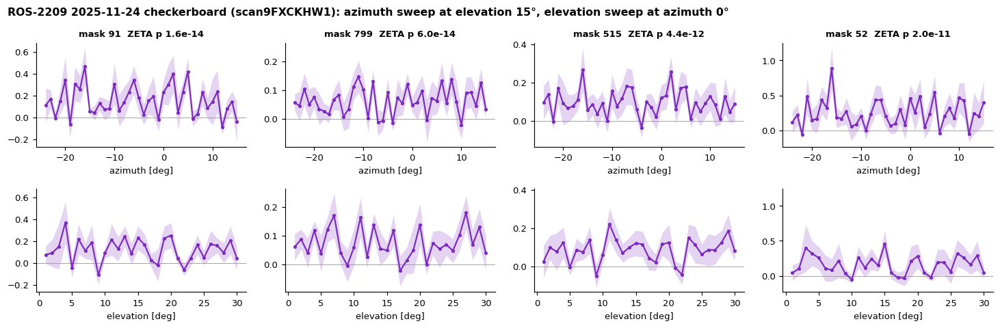

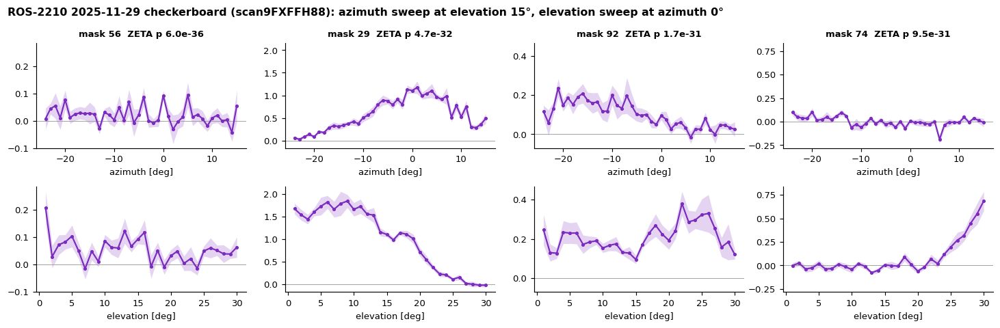

In [16]:
for _, row in REC[REC.paradigm == "rf"].iterrows():
    k = key(row)
    cc = pd.DataFrame((r.Readout.Condition & k & {"event_selector": "rf_checkerboard", "readout_idx": 1, "trace_source": "dff0_r2"}).fetch(as_dict=True))
    if not len(cc): print("no RF rows", row.scan_id); continue
    cc[["az", "el"]] = cc.condition.str.split("|", expand=True).astype(float); el0 = cc.el.mode().iloc[0]; az0 = cc.az.mode().iloc[0]
    zc = (r.Zeta.Cell * imaging.MaskClassification.MaskType & k & {"event_selector": "rf_checkerboard", "zeta_idx": 1, "trace_source": "oasis"} & 'mask_type="soma"').proj("zeta_p").fetch(format="frame").reset_index()
    top = zc.sort_values("zeta_p").head(4)["mask"].astype(int).tolist()
    fig, ax = plt.subplots(2, 4, figsize=(14, 4.6), sharey="col")
    for j, m in enumerate(top):
        d = cc[cc["mask"] == m]
        for i, (sw, axis, lab) in enumerate([(d[d.el == el0], "az", "azimuth"), (d[d.az == az0], "el", "elevation")]):
            sw = sw.sort_values(axis); a = ax[i, j]; a.axhline(0, color="#999", lw=.6)
            a.fill_between(sw[axis], sw.resp - sw.resp_sem, sw.resp + sw.resp_sem, color=COL["accent"], alpha=.2, lw=0); a.plot(sw[axis], sw.resp, color=COL["accent"], marker="o", ms=2.5)
            a.set(xlabel=f"{lab} [deg]")
        ax[0, j].set_title(f"mask {m}  ZETA p {zc.set_index('mask').loc[m, 'zeta_p']:.1e}", fontsize=9)
    fig.suptitle(f"{row.subject} {row.date} checkerboard ({row.scan_id}): azimuth sweep at elevation {el0:g}°, elevation sweep at azimuth {az0:g}°", x=.01, ha="left", fontweight="bold")
    plt.tight_layout(); plt.show()

## 11. Every tested window, evaluated

All read-out windows of the pilot, side by side, on the same cells and trials:

| read-out | paradigm | response | baseline | origin |
|---|---|---|---|---|
| 1 | all | [onset, offset), screen time | [onset − 0.5 s, onset) | generic |
| 2 | gratings | frames [on, on + n) | same length, ending 1 frame before onset | Leon's grating export (audit 234/234) |
| 4 | gratings | [onset, onset + 0.5 s) | [onset − 0.5 s, onset) | early response |
| 5 | gratings | [offset, offset + 1 s) | [onset − 0.5 s, onset) | OFF response |
| 8 | all | [onset + 0.1, onset + 2.0 s) | [onset − 1.0, onset − 0.1 s) | example window |
| 9 | gratings | peak (100 ms boxcar) in [+0.1, +2.0 s) | same peak, [−2.0, −0.1 s) | peak read-out |
| 10 | gratings | stimulus on screen, frames [on, off), minus the baseline | 30 frames (1 s) ending 2 frames before onset | your window, baseline-subtracted trials |
| 15 | gratings | stimulus on screen, frames [on, off), raw | 30 frames (1 s) ending 2 frames before onset (test only) | your window, raw trials |
| **16** | gratings | **stimulus on screen, frames [on, off), raw** | **frames [on − 60, on − 10) = −2.0 to −0.33 s (test only)** | **standard: baseline after the OFF decay, before CASCADE's pre-onset rise** |
| 3 | images | frames [on + 3, on + 3 + n), raw | — | Leon's image export (Slack 2026-09-24) |
| 7 | images | frames [on + 1, on + 15), raw | — | audit CASCADE 'opt' trees |
| **11** | images | **frames [on − 1, on + 15), raw** | — | **audit LOAO consensus for CASCADE (= Slack GCaMP6 start)** |
| 12 | images | frames [on, on + 16), raw | — | Slack: CASCADE common-default start 0 |
| 13 | images | frames [on + 1, on + 17), raw | — | Slack: CASCADE GCaMP8 start +1 |
| 14 | images | frames [on + 3, off + 3) | mean of [on, on + 3) | Leon's MEI restimulation (Slack 2026-11-12) |

Criteria, in order: **(1) calibration** — with random onsets the fraction of soma cells with p < 0.05 must stay ≈ 5 %
(a window that calls noise responsive is out); **(2) reliability** — the leave-one-repeat-out oracle over the
repeated conditions (12 directions × 15 repeats; 100 images × 10 repeats); **(3) sensitivity** — fraction of soma
cells called responsive / selective with real onsets; **(4) timing** — the window must not contain response before
the stimulus is on screen (CASCADE's non-causal kernel) and, for images, not the neighbouring single images.

### Where a grating baseline can sit: OFF decay and CASCADE's pre-onset rise

Frame-level population mean (z per cell) of the 40 most responsive soma cells per grating recording, aligned to the
**on-screen onset frame** (photodiode latency, else 100 ms), from the previous stimulus' offset (−120 frames) to +10.
Left: the previous OFF response decays; dashed = 10 % of its amplitude above the pre-onset plateau. Right: zoom on the
last 16 frames — CASCADE (non-causal kernel) rises from about −7 frames, OASIS and dF/F0 from 0. The grey band is the
standard baseline [on − 60, on − 10).

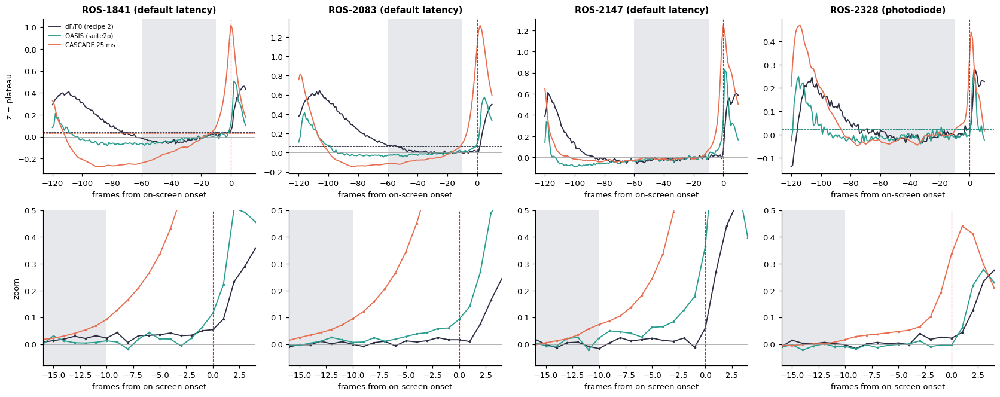

In [17]:
def onset_profiles(row, n=40):
    k = key(row); tm = timing(k, row.selector); ft = frame_times(k)
    scr = tm["screen_on"][1:]; on = np.array([int(np.argmin(np.abs(ft - t))) for t in scr])
    z = (r.Zeta.Cell * imaging.MaskClassification.MaskType & k & {"event_selector": row.selector, "trace_source": "oasis", "zeta_idx": 1}
         & 'mask_type="soma"' & "zeta_p < 0.001").fetch("mask", order_by="zeta_p", limit=n)
    L = np.arange(-120, 11); out = {}
    for src in ("dff0_r2", "oasis", "cascade25"):
        P = []
        for m in z:
            x = trace(k, int(m), src)[:len(ft)]; x = (x - np.nanmean(x)) / (np.nanstd(x) or 1)
            P.append(np.nanmean(x[np.clip(on[:, None] + L[None, :], 0, len(x) - 1)], 0))
        out[src] = np.nanmean(P, 0)
    return L, out

fig, ax = plt.subplots(2, 4, figsize=(16, 6.4), gridspec_kw=dict(height_ratios=[1, 1]))
for j, (_, row) in enumerate(REC[REC.paradigm == "gratings"].iterrows()):
    L, prof = onset_profiles(row)
    for src, v in prof.items():
        pl = v[(L >= -24) & (L <= -12)].mean(); v = v - pl
        for a in (ax[0, j], ax[1, j]): a.plot(L, v, color=COL[src], lw=1.3, marker="." if a is ax[1, j] else None, ms=3, label=LBL[src])
        amp = v[L < -60].max(); ax[0, j].axhline(.1 * amp, color=COL[src], lw=.6, ls="--")
    for a in (ax[0, j], ax[1, j]):
        a.axvspan(-60, -10, color="#adb5bd", alpha=.3, lw=0); a.axvline(0, color=COL["led"], lw=.8, ls="--"); a.axhline(0, color="#999", lw=.5)
    ax[0, j].set(title=f"{row.subject} ({'photodiode' if row.has_diode else 'default latency'})", xlabel="frames from on-screen onset")
    ax[1, j].set(xlim=(-16, 4), ylim=(-.08, .5), xlabel="frames from on-screen onset")
ax[0, 0].set_ylabel("z − plateau"); ax[1, 0].set_ylabel("zoom"); ax[0, 0].legend(fontsize=7); plt.tight_layout(); plt.show()

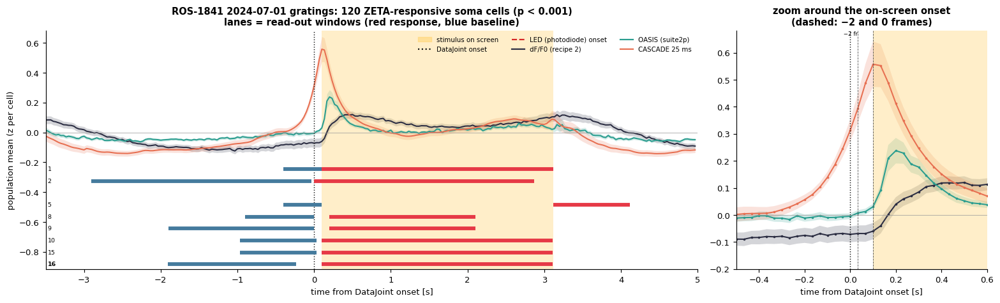

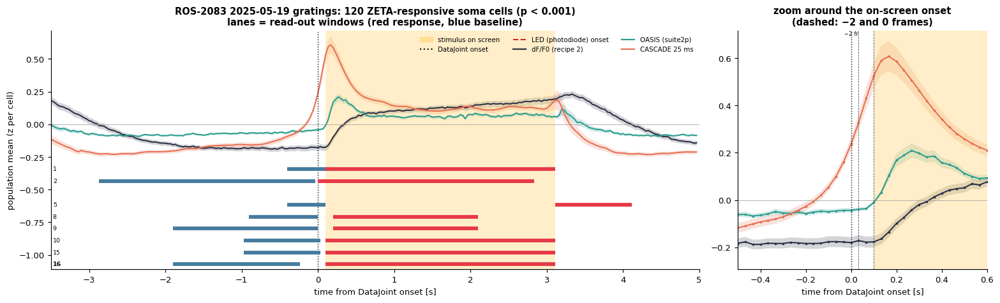

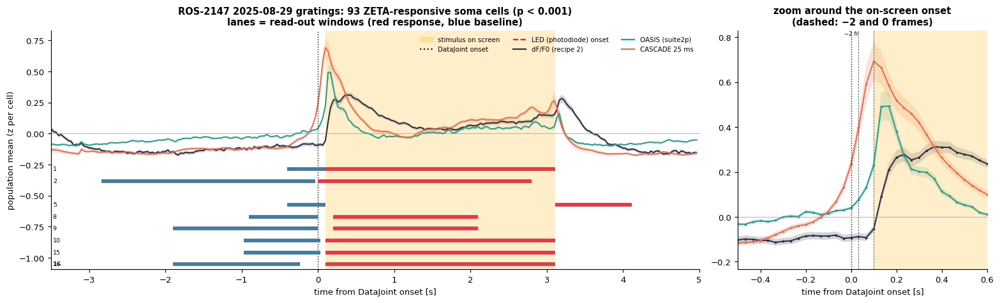

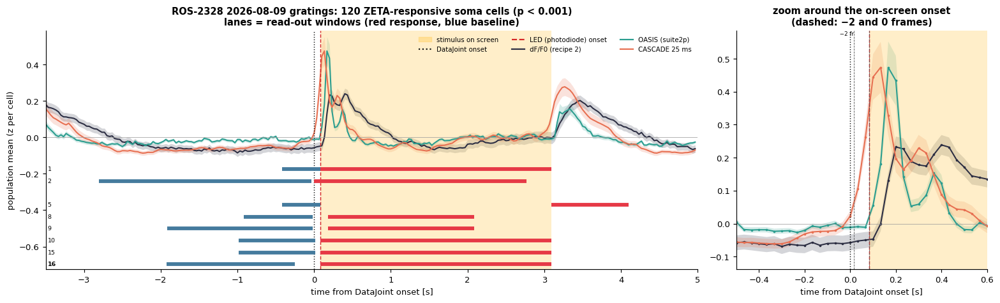

In [18]:
# ---- population PSTHs with every window as a lane --------------------------------------------------------------
GR_W = [1, 2, 4, 5, 8, 9, 10, 15, 16]; IM_W = [1, 3, 7, 8, 11, 12, 13, 14]
WCOL = plt.cm.tab10(np.arange(10))

def pop(k, sel, src, masks, pre, post):
    ft = frame_times(k); t0 = timing(k, sel)["t0"]; out = []
    for m in masks:
        x = trace(k, m, src); x = (x - np.nanmean(x)) / (np.nanstd(x) or 1)
        g, M = peri(x, ft, t0, pre, post); out.append(np.nanmean(M, 0))
    return g, np.vstack(out)

def lanes(ax, k, sel, src, ws, y0, dy):
    for j, i in enumerate(ws):
        e = readout_row(k, sel, src, i)
        if e is None: continue
        y = y0 - j * dy
        ax.plot([e["resp_start_s"], e["resp_stop_s"]], [y, y], color=COL["resp"], lw=4, solid_capstyle="butt")
        if e["base_stop_s"] is not None: ax.plot([e["base_start_s"], e["base_stop_s"]], [y, y], color=COL["base"], lw=4, solid_capstyle="butt")
        ax.text(0.003, y, f"{i}", va="center", ha="left", fontsize=6.5, transform=ax.get_yaxis_transform(),
                fontweight="bold" if i in (16, 3, 11) else "normal")

def window_figure(row, ws, pre, post, zoom=(-0.5, 0.6)):
    k = key(row); sel = row.selector; tm = timing(k, sel)
    z = (r.Zeta.Cell * imaging.MaskClassification.MaskType & k & {"event_selector": sel, "trace_source": "oasis", "zeta_idx": 1}
         & 'mask_type="soma"' & "zeta_p < 0.001").fetch("mask")
    if len(z) < 3: print("few responsive cells", row.scan_id); return
    masks = [int(m) for m in z[:120]]
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw=dict(width_ratios=[2.6, 1]))
    for src in ("dff0_r2", "oasis", "cascade25"):
        g, P = pop(k, sel, src, masks, pre, post); m_ = P.mean(0); s_ = P.std(0) / np.sqrt(len(P))
        for a in ax:
            a.fill_between(g, m_ - s_, m_ + s_, color=COL[src], alpha=.2, lw=0); a.plot(g, m_, color=COL[src], lw=1.4, label=LBL[src])
            if a is ax[1]: a.plot(g, m_, ".", color=COL[src], ms=3)
    lo = ax[0].get_ylim()[0]; top = ax[0].get_ylim()[1]
    for a in ax:
        mark_psth(a, tm); a.axhline(0, color="#999", lw=.5)
    ax[0].set_ylim(lo - .09 * (top - lo) * len(ws), top); lanes(ax[0], k, sel, "cascade25" if row.paradigm == "images" else "dff0_r2", ws, lo - .05 * (top - lo), .09 * (top - lo))
    if row.paradigm == "images":   # OASIS / dF/F0 windows differ from CASCADE only for 11-13 (CASCADE-only) — lanes are drawn from the CASCADE rows
        pass
    ft = frame_times(k); dt = float(np.median(np.diff(ft)))
    for f_ in (-2, 0):
        ax[1].axvline(tm["lat"] + f_ * dt, color="#555", lw=.6, ls="--")
    ax[1].text(tm["lat"] - 2 * dt, ax[1].get_ylim()[1], " −2 fr", fontsize=6, va="top", ha="right")
    ax[1].set(xlim=zoom, title="zoom around the on-screen onset\n(dashed: −2 and 0 frames)", xlabel="time from DataJoint onset [s]")
    ax[0].set(xlim=(-pre, post), xlabel="time from DataJoint onset [s]", ylabel="population mean (z per cell)",
              title=f"{row.subject} {row.date} {row.paradigm}: {len(masks)} ZETA-responsive soma cells (p < 0.001)\nlanes = read-out windows (red response, blue baseline)")
    ax[0].legend(handles=LEGEND[:3] + [Line2D([], [], color=COL[s], label=LBL[s]) for s in ("dff0_r2", "oasis", "cascade25")], fontsize=7, ncol=3, loc="upper right")
    plt.tight_layout(); plt.show()

for _, row in REC[REC.paradigm == "gratings"].iterrows():
    try: window_figure(row, GR_W, 3.5, 5.0)
    except Exception as e: print("skipped", row.scan_id, repr(e)[:200])

Images: lanes from the CASCADE rows (read-outs 11–13 exist for CASCADE only; 3 and 14 are the same frames on every trace).
The population PSTH extends over the neighbouring single images (≈ −0.9 s and +0.9 s), which is why no image read-out
uses a pre-stimulus baseline except Leon's 3-frame MEI baseline (14).

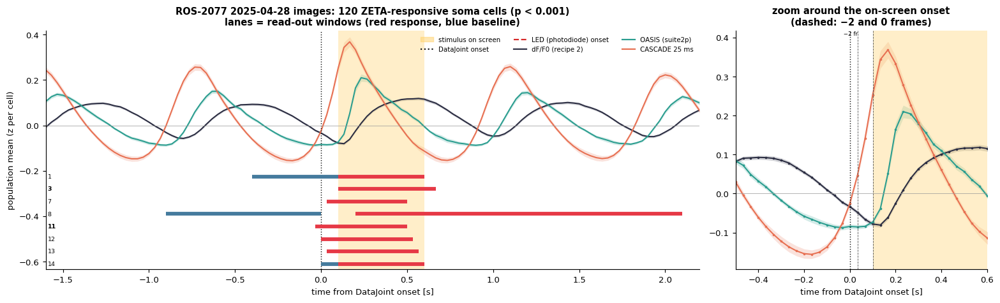

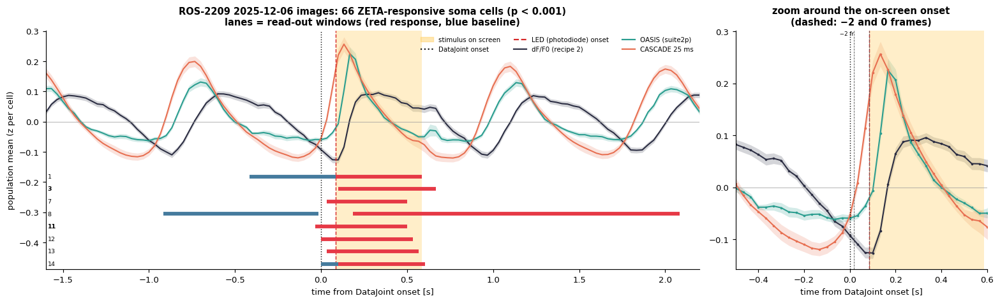

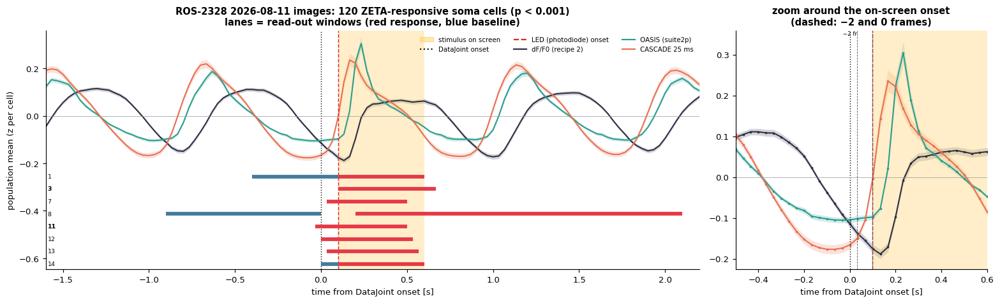

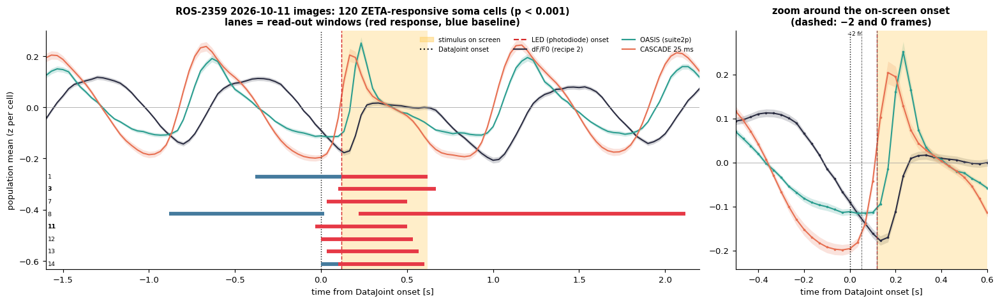

In [19]:
for _, row in REC[REC.paradigm == "images"].iterrows():
    try: window_figure(row, IM_W, 1.6, 2.2)
    except Exception as e: print("skipped", row.scan_id, repr(e)[:200])

### Single cells under every window

Per paradigm, the strongest, a median and a weak ZETA-responsive cell of one recording: PSTH (dF/F0 and CASCADE)
with each window's per-trial value distribution (box per read-out; trial value = the stored `trial_resp`).

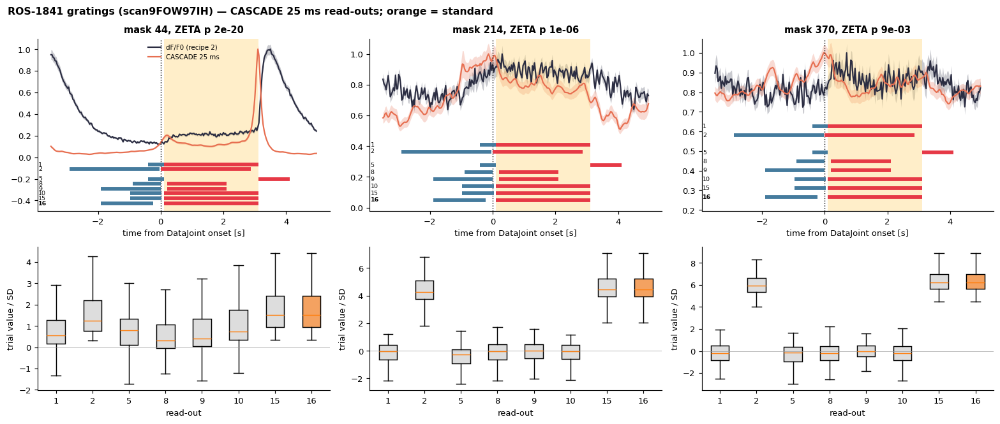

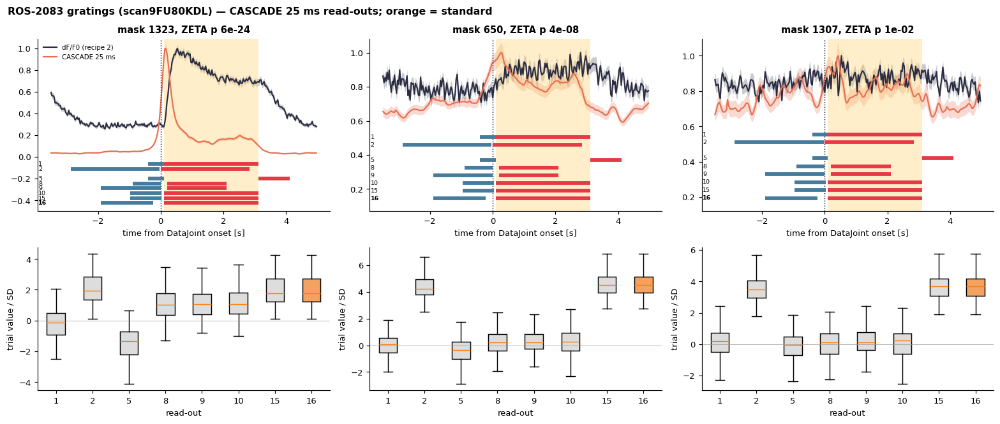

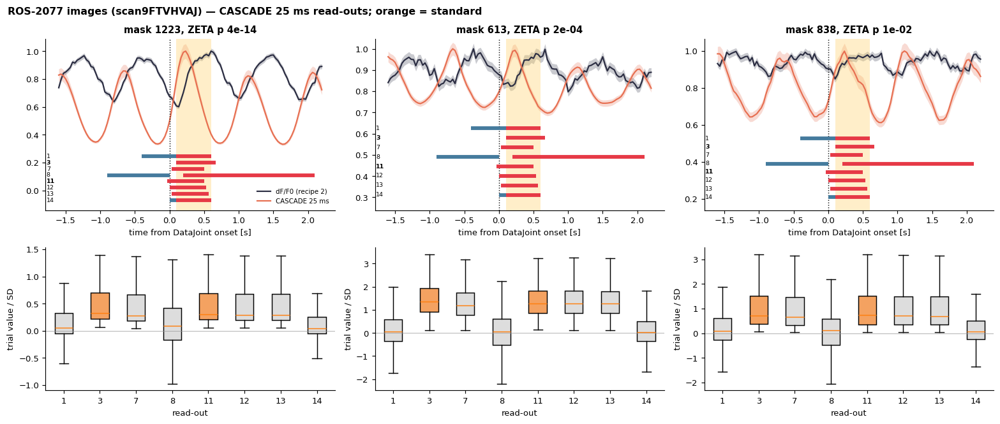

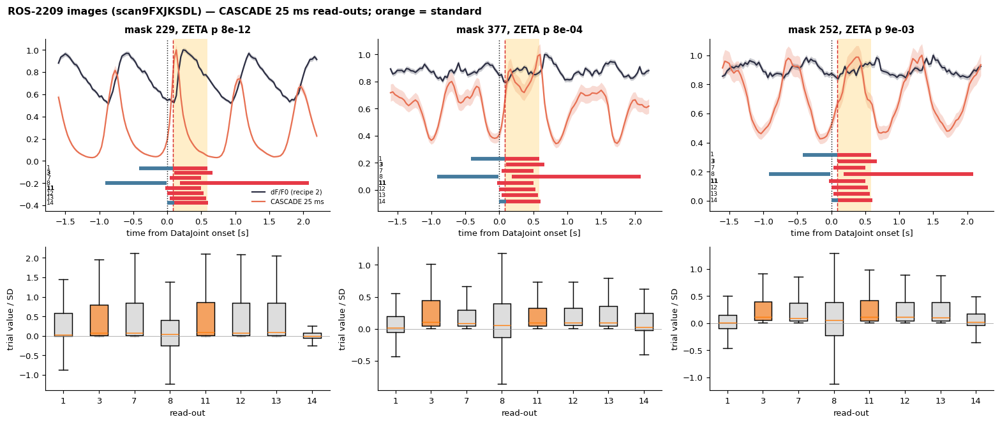

In [20]:
def cell_windows(row, ws, src, pre, post):
    k = key(row); sel = row.selector; tm = timing(k, sel); ft = frame_times(k)
    z = (r.Zeta.Cell * imaging.MaskClassification.MaskType & k & {"event_selector": sel, "trace_source": "oasis", "zeta_idx": 1}
         & 'mask_type="soma"').proj("zeta_p").fetch(format="frame").reset_index().sort_values("zeta_p")
    z = z[z.zeta_p < .01]; picks = [z.iloc[0], z.iloc[len(z) // 2], z.iloc[-1]]
    fig, ax = plt.subplots(2, 3, figsize=(15, 6.4), gridspec_kw=dict(height_ratios=[1.2, 1]))
    for j, pk in enumerate(picks):
        m = int(pk["mask"]); a = ax[0, j]
        for s_ in ("dff0_r2", src):
            g, M = peri(trace(k, m, s_), ft, tm["t0"], pre, post); psth(a, g, M, COL[s_], LBL[s_], scale=True)
        mark_psth(a, tm); a.set(title=f"mask {m}, ZETA p {pk.zeta_p:.0e}", xlabel="time from DataJoint onset [s]")
        lo = a.get_ylim()[0]; a.set_ylim(lo - .045 * (len(ws) + 1.5), a.get_ylim()[1]); lanes(a, k, sel, src, ws, lo - .04, .045)
        vals, labs = [], []
        for i in ws:
            q = r.Readout.Cell & k & {"event_selector": sel, "trace_source": src, "readout_idx": i, "mask": m, "fluo_channel": 0}
            if not q: continue
            t = np.asarray(q.fetch1("trial_resp"), float); t = t[np.isfinite(t)]
            vals.append(t / (np.nanstd(t) or 1)); labs.append(str(i))
        b = ax[1, j]; bp = b.boxplot(vals, labels=labs, showfliers=False, patch_artist=True)
        for patch, i in zip(bp["boxes"], labs): patch.set_facecolor("#f4a261" if i in ("16", "11", "3") else "#ddd")
        b.axhline(0, color="#999", lw=.5); b.set(xlabel="read-out", ylabel="trial value / SD")
    ax[0, 0].legend(fontsize=7); fig.suptitle(f"{row.subject} {row.paradigm} ({row.scan_id}) — {LBL[src]} read-outs; orange = standard", x=.01, ha="left", fontweight="bold")
    plt.tight_layout(); plt.show()

for par, ws, pre, post in (("gratings", GR_W, 3.5, 5.0), ("images", IM_W, 1.6, 2.2)):
    for _, row in REC[REC.paradigm == par].head(2).iterrows():
        try: cell_windows(row, ws, "cascade25", pre, post)
        except Exception as e: print("skipped", row.scan_id, repr(e)[:200])

### Metrics per window

`fpr` = fraction of soma cells with p < 0.05 on random onsets (the `*_random` control recordings); `responsive` =
p < 0.05 with real onsets; `selective` = Kruskal–Wallis across conditions p < 0.01 (`cond_kw_p`); `oracle` = median
leave-one-repeat-out r; `snr` = median response SNR across condition means; `d` = median effect size. Medians over
the soma cells of every recording of the paradigm.

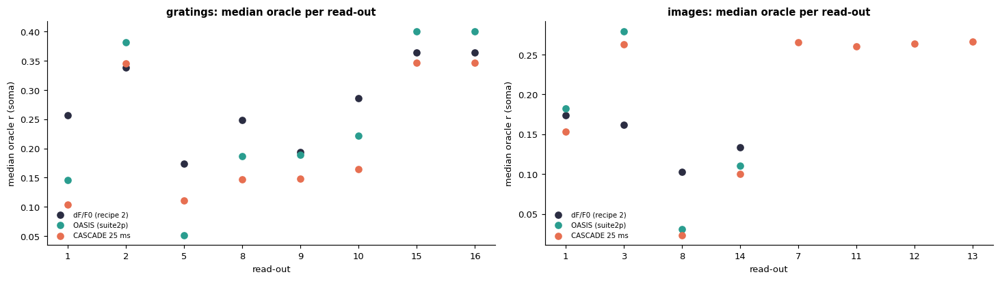

In [21]:
cols = ["resp_p", "cond_kw_p", "oracle_r", "response_snr", "effect_d"]
A = pd.DataFrame((r.Readout.Cell & "fluo_channel = 0").proj(*cols).fetch(as_dict=True)).merge(somas, on=["scan_id", "curation_id", "mask"])
A["random"] = A.event_selector.str.endswith("_random"); A["paradigm"] = A.event_selector.str.replace("_random", "")
def summarise(par, ws):
    d = A[(A.paradigm == par) & A.readout_idx.isin(ws)]
    real, rnd = d[~d.random], d[d.random]
    g = real.groupby(["readout_idx", "trace_source"]).agg(responsive=("resp_p", lambda p: np.mean(p < .05) if p.notna().any() else np.nan),
          selective=("cond_kw_p", lambda p: np.mean(p < .01)), oracle=("oracle_r", "median"), snr=("response_snr", "median"), d=("effect_d", "median"))
    f = rnd.groupby(["readout_idx", "trace_source"]).resp_p.apply(lambda p: np.mean(p < .05) if p.notna().any() else np.nan).rename("fpr")
    return g.join(f).reset_index()
GT = summarise("gratings", GR_W); IT = summarise("nat_images_repeated", IM_W)
fmt = {"responsive": "{:.0%}", "selective": "{:.0%}", "fpr": "{:.1%}", "oracle": "{:.3f}", "snr": "{:.2f}", "d": "{:.2f}"}
for name, T in (("gratings", GT), ("images", IT)):
    display(T.pivot(index="readout_idx", columns="trace_source", values=["fpr", "responsive", "selective", "oracle", "snr"])
            .style.format(lambda v: "" if pd.isna(v) else (f"{v:.3f}" if abs(v) < 1 and v != 0 else f"{v:.3g}")).set_caption(f"{name}: per read-out and trace"))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, (name, T) in zip(ax, (("gratings", GT), ("images", IT))):
    for src in ("dff0_r2", "oasis", "cascade25"):
        t = T[T.trace_source == src]
        a.scatter(t.readout_idx.astype(str), t.oracle, color=COL[src], s=40, label=LBL[src])
    a.set(title=f"{name}: median oracle per read-out", xlabel="read-out", ylabel="median oracle r (soma)"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

### Decision

Applied in code: a window is admissible on a trace if its random-onset false-positive rate there is ≤ 7 % (windows
without a baseline are levels, not tests, and are judged by the oracle only); among admissible windows the one with the
highest median oracle wins, and the standard window is kept unless another beats it by more than 0.01 (the audit's
grid-search inflation of the maximum).

In [22]:
def decide(T, standard):
    rows = []
    for src, d in T.groupby("trace_source"):
        adm = d[(d.fpr.isna()) | (d.fpr <= .07)]
        best = adm.sort_values("oracle", ascending=False).iloc[0]
        std_i = standard(src); s_ = d[d.readout_idx == std_i]
        s_or = float(s_.oracle.iloc[0]) if len(s_) else np.nan
        keep = len(s_) and (std_i in adm.readout_idx.values) and (best.oracle - s_or <= .01)
        rows.append(dict(trace=src, standard=std_i, standard_oracle=round(s_or, 3), standard_fpr=None if s_.empty else s_.fpr.iloc[0],
                         best_admissible=int(best.readout_idx), best_oracle=round(float(best.oracle), 3),
                         excluded=sorted(set(d.readout_idx) - set(adm.readout_idx)), decision=f"keep {std_i}" if keep else f"use {int(best.readout_idx)}"))
    return pd.DataFrame(rows)
display(decide(GT, lambda s: 16).style.set_caption("gratings (dF/F0: read-out 16 exceeds 7 % false positives - not for calls)"))
display(decide(IT, lambda s: 11 if s == "cascade25" else 3).style.set_caption("images"))

,trace,standard,standard_oracle,standard_fpr,best_admissible,best_oracle,excluded,decision
0,cascade25,16,0.347000,0.035294,15,0.347000,"[1, 5]",keep 16
1,dff0_r2,16,0.364000,0.094118,15,0.364000,[16],use 15
2,oasis,16,0.401000,0.039216,15,0.401000,"[1, 5]",keep 16


,trace,standard,standard_oracle,standard_fpr,best_admissible,best_oracle,excluded,decision
0,cascade25,11,0.260000,nan,13,0.266000,[],keep 11
1,dff0_r2,3,0.162000,nan,1,0.174000,[],use 1
2,oasis,3,0.279000,nan,3,0.279000,[],keep 3


### What was decided, and why

**Gratings — read-out 16 on CASCADE and OASIS:** response = the stimulus on screen, frames [on, off), each trial's
**raw** mean; baseline = frames [on − 60, on − 10) (−2.0 to −0.33 s), used **only by the test** (paired t, response vs
baseline).

* *Raw trial values, not baseline-subtracted.* With the same response window, subtracting a 1 s baseline from every
  trial (read-out 10) halves the oracle (CASCADE 0.17 vs 0.35, OASIS 0.22 vs 0.40) and the fraction of selective cells
  (38 vs 67 %): the baseline adds its own noise to every trial. Raw values on the on-screen window (15, 16) also beat
  Leon's export window (2) on every trace (oracle 0.347 / 0.401 / 0.364 vs 0.346 / 0.382 / 0.338), and call more cells
  responsive at a calibrated false-positive rate.
* *Baseline after the OFF decay.* The previous grating's OFF response peaks ~116 frames before the next onset and
  decays below 10 % by frame −92 … −104 (OASIS, CASCADE) and −63 … −74 (dF/F0; −98 in ROS-2147): the baseline starts at
  −60 (section "Where a grating baseline can sit"). Caveat: on ROS-1841 and ROS-2083 CASCADE undershoots after the OFF
  response (to about −0.25 z below the pre-onset plateau) and is still recovering inside [−60, −10). The test then
  compares the response with a slightly low baseline, a bias that random onsets cannot show; it affects only `resp_p`,
  not the raw trial values used for tuning and the oracle.
* *Baseline before CASCADE's pre-onset rise.* CASCADE's non-causal kernel lifts the trace from about −7 frames before
  the on-screen onset (photodiode recording ROS-2328: 2 % of its peak at −10), OASIS and dF/F0 from 0. Ending the
  baseline at −10 instead of −2 (read-out 15) raises CASCADE's responsive fraction from 70 to 79 % and OASIS's from 76 to
  82 % at 3.5–3.9 % false positives.
* *Not on dF/F0 for calls.* dF/F0 drifts slowly; with the baseline 2 s away its random-onset rate rises to 9.4 % (15:
  6.7 %). Use CASCADE / OASIS (or ZETA) for responsiveness; dF/F0 for display. If a dF/F0 test is ever needed, the
  rule in the table above picks read-out 15 (baseline [−32, −2), same trial values).
* *Tuning:* `DirectionTuning` on read-out 16 (tuning 1: Mazurek et al. 2014 indices on rectified condition means). The
  audit's own convention (read-out 2, OASIS, tuning 2) remains for the comparison in section 7 and agrees exactly.

**Images — read-out 3 on OASIS, read-out 11 on CASCADE; responsiveness by ZETA (or read-out 14), reliability by the oracle.**

* No pre-stimulus baseline: the grey gap still holds the previous single image's response (≈ ±0.9 s, section 4), and
  read-out 8's baseline makes it no better than chance (4 % with real onsets).
* CASCADE start offset does not matter: windows 3, 7, 11, 12, 13 reach oracle 0.260–0.266, a spread below the 0.01 a
  grid search gains by chance — the audit's consensus window (11, frames [on − 1, on + 15)) is kept; per animal the best
  start differs (ROS-2077: 11; ROS-2328 / 2359: 3 or 13) without an indicator pattern.
* OASIS: Leon's window (3) is best (0.279). dF/F0 is the weakest image signal (0.16–0.17); the rule prefers read-out 1
  (on-screen window, 0.174 vs 0.162) for it, a gain within the 0.01 grid-search noise, and dF/F0 is not used for image calls.
* Leon's MEI restimulation window (14: [on + 3, off + 3) − [on, on + 3)) is a calibrated test (4–7 %) that calls 67–76 %
  of soma cells responsive vs 31–40 % for ZETA, at a lower oracle (0.10–0.13) — use it as the image responsiveness
  test where a per-trial test is needed, ZETA where the response shape is unknown.

**Checkerboard — read-out 1** (no export window; calibrated 4–7 %), pending a dedicated evaluation.

## 12. Summary per recording, and how to query

Fraction of soma cells passing each level, per recording: QC (raw kurtosis ≥ 5), active (dF/F0 SNR ≥ 0.2), responsive
(ZETA on OASIS p < 0.05), tuned (gratings: Kruskal–Wallis across orientations < 0.01, CASCADE, read-out 16), reliable (images: OASIS oracle ≥ 0.2, read-out 3). These are
queries over the tables; `CellRule` stores such thresholds by name and `cells(rule)` applies them.

In [23]:
out = []
for _, row in REC.iterrows():
    k = key(row); s = soma(k)
    qcd = pd.DataFrame((r.Quality.Cell & k).proj("kurtosis").fetch(as_dict=True)); qcd = qcd[qcd["mask"].isin(s)]
    tqd = pd.DataFrame((r.TraceQuality.Cell & k & {"trace_source": "dff0_r2"}).proj("snr_s2p").fetch(as_dict=True)); tqd = tqd[tqd["mask"].isin(s)]
    zd = pd.DataFrame((r.Zeta.Cell & k & {"event_selector": row.selector, "trace_source": "oasis", "zeta_idx": 1}).proj("zeta_p").fetch(as_dict=True))
    d = dict(recording=f"{row.subject} {row.date}", paradigm=row.paradigm, soma=len(s), latency=("photodiode" if row.has_diode else "default"),
             qc=f"{(qcd['kurtosis'] >= 5).mean():.0%}", active=f"{(tqd.snr_s2p >= .2).mean():.0%}", responsive=f"{(zd.zeta_p < .05).mean():.0%}" if len(zd) else "")
    if row.paradigm == "gratings":
        t_ = pd.DataFrame((r.DirectionTuning.Cell & k & TUNE).proj("ori_kw_p").fetch(as_dict=True)); t_ = t_[t_["mask"].isin(s)]
        d["tuned"] = f"{(t_.ori_kw_p < .01).mean():.0%}"
    if row.paradigm == "images":
        o_ = pd.DataFrame((r.Readout.Cell & k & {"event_selector": "nat_images_repeated", "readout_idx": 3, "trace_source": "oasis"}).proj("oracle_r").fetch(as_dict=True)); o_ = o_[o_["mask"].isin(s)]
        d["reliable"] = f"{(o_.oracle_r >= .2).mean():.0%}"
    out.append(d)
pd.DataFrame(out).fillna("")

,recording,paradigm,soma,latency,qc,active,responsive,tuned,reliable
0,ROS-1841 2024-07-01,gratings,510,default,74%,56%,92%,63%,
1,ROS-2083 2025-05-19,gratings,581,default,65%,60%,97%,75%,
2,ROS-2147 2025-08-29,gratings,97,default,47%,47%,99%,66%,
3,ROS-2328 2026-08-09,gratings,603,photodiode,47%,59%,94%,57%,
4,ROS-2077 2025-04-28,images,1005,default,85%,91%,77%,,67%
5,ROS-2209 2025-12-06,images,513,photodiode,49%,57%,40%,,20%
6,ROS-2328 2026-08-11,images,599,photodiode,65%,97%,87%,,77%
7,ROS-2359 2026-10-11,images,606,photodiode,74%,91%,88%,,76%
8,ROS-2209 2025-11-24,rf,468,photodiode,57%,53%,40%,,
9,ROS-2210 2025-11-29,rf,405,photodiode,42%,43%,93%,,


```python
# responsive soma cells of a curation on CASCADE, with their tuning on the standard grating window (read-out 16, tuning 1)
q = (r.Zeta.Cell & curation & {"trace_source": "cascade25", "event_selector": "gratings", "zeta_idx": 1} & "zeta_p < 0.01") \
    * (r.DirectionTuning.Cell & {"readout_idx": 16, "tuning_idx": 1}).proj("ori_vec", "dir_vec", "ori_kw_p", "fit_pref_dir")

# per-trial responses with the trial, stimulus string, DataJoint and LED times of every onset
tr = (r.Readout.Cell & cell & {"readout_idx": 16}).fetch1("trial_resp")      # gratings, standard window
on = (r.EventSet.Onset * trial.Trial * event.Event * r.ScreenTiming.Onset & cell).fetch(
     "onset_idx", "trial_id", "event_type", "event_start_time", "diode_on", order_by="onset_idx")

# a window of your own: baseline 1.0-0.1 s before, response 0.1-2.0 s after onset (screen time), peak = read-out 9
resp.plan_tasks(curations, ["cascade25", "oasis"], ["gratings"], readouts=[9], zetas=[1], owner="me")
```